# Sentinel-2 mineral mapping
## Tharsis-Lagunazo, Iberian Pyrite Belt, SW Spain

## 0 · Environment check and plotting style

In [ ]:
import os, sys, importlib
from importlib import metadata as _metadata

REQUIRED = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn",
            "matplotlib": "matplotlib", "rasterio": "rasterio"}
OPTIONAL = {"contextily": "contextily"}                        # Esri basemap only
IS_CONDA = os.path.isdir(os.path.join(sys.prefix, "conda-meta"))

def _check_packages():
    missing, broken = [], []
    for mod, pkg in {**REQUIRED, **OPTIONAL}.items():
        required = mod in REQUIRED
        try:
            version = getattr(importlib.import_module(mod), "__version__", "")
            print(f"  ok        {mod:<11} {version}")
        except ModuleNotFoundError as err:
            top = (err.name or "").split(".")[0]
            if err.name == mod:                                 # package not installed
                print(f"  {'MISSING' if required else 'absent':<9} {mod}"
                      + ("" if required else "   (optional: only needed for BASEMAP = 'esri')"))
                if required:
                    missing.append(pkg)
            elif top != mod and top in REQUIRED:                # fails only because another package is broken
                print(f"  BROKEN    {mod:<11} because {top} is broken (fixed together with {top})")
            else:                                               # installed, but a file inside it is missing
                print(f"  BROKEN    {mod:<11} {err}")
                if required:
                    broken.append(pkg)
        except Exception as err:                                # installed, but fails while importing
            print(f"  BROKEN    {mod:<11} {type(err).__name__}: {err}")
            if required:
                broken.append(pkg)
    return missing, broken

def _pinned(pkg):
    try:
        return f'"{pkg}=={_metadata.version(pkg)}"'              # reinstall the version already recorded
    except Exception:
        return pkg

def _fix_instructions(missing, broken, is_conda):
    exe = f'"{sys.executable}"'
    repair = f"--force-reinstall --no-deps {' '.join(_pinned(p) for p in broken)}" if broken else ""
    add = [p for p in missing if not (is_conda and p == "rasterio")]
    lines = ["This kernel's Python environment is incomplete.",
             "Fix from the notebook: RESTART THE KERNEL, then run ONLY a new first cell containing:"]
    if repair:
        lines.append(f"    %pip install {repair}")
    if add:
        lines.append(f"    %{'conda install -y' if is_conda else 'pip install'} {' '.join(add)}")
    lines += ["  then restart the kernel again and run the notebook from the top.",
              "If that reports 'Access is denied': close VS Code and run the same in a terminal"
              + (" (Anaconda Prompt, as administrator)" if is_conda else "") + ":"]
    if repair:
        lines.append(f"    {exe} -m pip install {repair}")
    if add:
        lines.append(f"    {'conda install -y -p ' + chr(34) + sys.prefix + chr(34) if is_conda else exe + ' -m pip install'} {' '.join(add)}")
    if is_conda and "rasterio" in missing:
        lines += ["rasterio (with GDAL) is safest in its own conda-forge environment:",
                  "    conda create -y -n sentinel2 -c conda-forge python=3.12 numpy pandas scipy scikit-learn "
                  "matplotlib rasterio contextily ipykernel",
                  "  then select the 'sentinel2' kernel for this notebook."]
    return "\n".join(lines)

print(f"Python {sys.version.split()[0]}  ·  {sys.executable}  ·  {'conda' if IS_CONDA else 'pip'} environment")
_missing, _broken = _check_packages()
if _missing or _broken:
    raise RuntimeError(_fix_instructions(_missing, _broken, IS_CONDA))
print("Environment OK")

# Core scientific stack
import re, math, textwrap, zipfile, datetime
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.patches import FancyArrow, Rectangle
from matplotlib.ticker import FuncFormatter, MaxNLocator

import rasterio
from rasterio.features import geometry_mask
from rasterio.transform import from_origin
from rasterio.warp import transform_geom, transform_bounds, reproject, Resampling
from rasterio.warp import transform as warp_transform
from rasterio.windows import Window, from_bounds
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

FIG_DPI      = 400             # export resolution for every PNG
NODATA_COLOR = "#f2f1ee"       # neutral fill for masked pixels in panel figures

# Chart colours: validated categorical order; text stays in ink colours, never series colours
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
DIVERGING = LinearSegmentedColormap.from_list("blue_grey_red", ["#2a78d6", "#f0efec", "#e34948"])
SEQ_BLUE  = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#2a78d6", "#0d366b"])

plt.rcParams.update({
    "figure.dpi"         : 120,
    "savefig.dpi"        : FIG_DPI,
    "savefig.bbox"       : "tight",
    "savefig.pad_inches" : 0.05,
    "figure.facecolor"   : "white",
    "savefig.facecolor"  : "white",
    "font.family"        : "DejaVu Sans",
    "font.size"          : 10,
    "axes.titlesize"     : 12,
    "axes.titleweight"   : "bold",
    "axes.labelsize"     : 10,
    "axes.linewidth"     : 0.9,
    "axes.edgecolor"     : "0.12",
    "xtick.labelsize"    : 8,
    "ytick.labelsize"    : 8,
    "xtick.direction"    : "out",
    "ytick.direction"    : "out",
    "xtick.major.size"   : 3.5,
    "ytick.major.size"   : 3.5,
    "grid.color"         : GRID,
    "grid.linewidth"     : 0.6,
    "grid.linestyle"     : "-",
    "image.interpolation": "nearest",
    "legend.frameon"     : False,
    "mathtext.default"   : "regular",
    "pdf.fonttype"       : 42,          # editable text in the PDFs
})

def style_chart(ax, grid_axis="y"):
    """Recessive chart chrome: hairline solid grid, no top/right spines, ink-coloured text."""
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(True, axis=grid_axis, color=GRID, lw=0.6)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#c3c2b7")
    ax.tick_params(colors=INK_2, labelcolor=INK_2)
    ax.xaxis.label.set_color(INK); ax.yaxis.label.set_color(INK)
    ax.title.set_color(INK)

print(f"Plot style set  ·  export DPI = {FIG_DPI}")

Python 3.12.3  ·  c:\anaconda3\python.exe  ·  conda environment
  ok        numpy       1.26.4
  ok        pandas      3.0.2
  ok        scipy       1.15.2
  ok        sklearn     1.6.1
  ok        matplotlib  3.10.9
  ok        rasterio    1.4.3
  ok        contextily  1.6.2
Environment OK
Plot style set  ·  export DPI = 400


## 1 · Configuration

In [ ]:
#  CONFIG
SITE_NAME = "Tharsis-Lagunazo"

# INPUT BANDS: Copernicus Browser 'Raw' exports or ESA SAFE granule files (.jp2/.tif)
_BROWSER = "2026-04-03-00_00_2026-04-03-23_59_Sentinel-2_L1C_{}_(Raw).tiff"
BAND_FILES = {
    "B1" : _BROWSER.format("B01"),   # 60 m  coastal aerosol (context only)
    "B2" : _BROWSER.format("B02"),   # 10 m  blue
    "B3" : _BROWSER.format("B03"),   # 10 m  green
    "B4" : _BROWSER.format("B04"),   # 10 m  red
    "B5" : _BROWSER.format("B05"),   # 20 m  red edge 1
    "B6" : _BROWSER.format("B06"),   # 20 m  red edge 2
    "B7" : _BROWSER.format("B07"),   # 20 m  red edge 3
    "B8" : _BROWSER.format("B08"),   # 10 m  NIR (broad)
    "B8A": _BROWSER.format("B8A"),   # 20 m  narrow NIR
    "B9" : _BROWSER.format("B09"),   # 60 m  water vapour (context only)
    "B11": _BROWSER.format("B11"),   # 20 m  SWIR-1  <- not in the r3 download: export it
    "B12": _BROWSER.format("B12"),   # 20 m  SWIR-2  <- not in the r3 download: export it
}
SCL_FILE = None                      # L2A scene classification (class values 0-11), e.g. "..._SCL_20m.jp2"; None for L1C

# PRODUCT AND SCALING
PRODUCT_LEVEL = "auto"               # "auto" (from file names), "L1C" or "L2A"
REFL_SCALE    = "auto"               # "auto" or a number: 1e-4 (DN/10000), 1/65535 (16-bit Browser export), 1.0 (float)
DN_OFFSET     = "auto"               # "auto": -1000 for SAFE files from baseline 04.00 on; 0 for Browser exports
S2_PLATFORM   = "auto"               # "auto" (from SAFE names; otherwise S2B band centres), "S2A", "S2B" or "S2C"
ACQ_DATE      = "auto"               # "auto" (from file names) or "YYYY-MM-DD"
DOS_L1C       = True                 # L1C only: dark-object subtraction DOS1 (dark object keeps 1 % reflectance)
DOS_DARK_PERCENTILE = 0.1            # percentile of valid AOI pixels taken as the dark object

# AREA OF INTEREST AND ANALYSIS GRID
AOI_KMZ        = "aoi_boundary.kmz"  # .kmz/.kml polygon (EPSG:4326); None = extent of B4
TARGET_CRS     = "EPSG:32629"        # UTM zone 29N, WGS 84
ANALYSIS_RES_M = 20                  # 20 m recommended; 10 m for VNIR-only detail

# ANALYSIS MASKS
NDVI_VEG_THRESHOLD    = 0.30         # NDVI above this = vegetation
WATER_INDEX_THRESHOLD = 0.00         # MNDWI (B3, B11) with SWIR, otherwise NDWI (B3, B8); above this = water
WATER_NIR_MAX         = 0.15         # NIR (B8A or B8) below this, so bright white crusts are not water
DARK_REFL_MIN         = 0.01         # any analysis band below this = dark / shadow
DARK_NIR_MAX          = 0.04         # NIR (B8A or B8) below this = dark water or deep shadow
SCL_MASK_CLASSES = {0: "no data", 1: "saturated / defective", 3: "cloud shadow", 8: "cloud (medium)",
                    9: "cloud (high)", 10: "thin cirrus", 11: "snow / ice"}
SCL_WATER_CLASS, SCL_DARK_CLASS = 6, 2

# CRÓSTA (FEATURE-ORIENTED PCA)
CROSTA_STANDARDISE = True            # True = correlation-matrix PCA; False = covariance PCA
CROSTA_FE_PC = None                  # force a component (1-based) after reading the loadings
CROSTA_OH_PC = None

# ANOMALY THRESHOLDS AND ROBUSTNESS
SIGMA_LEVELS     = (1.0, 2.0)        # mean + k·sigma
CA_N_THRESHOLDS  = 120               # thresholds sampled for the concentration–area plot
TOP_PERCENT      = 10                # top-x % masks for method overlap (Jaccard)
NDVI_SENSITIVITY = (0.20, 0.25, 0.30, 0.35, 0.40)
RANDOM_STATE     = 42

# SPECTRAL LIBRARY SAM (optional)
LIBRARY_CSV          = None          # CSV: mineral + the SAM band columns (e.g. B2,B3,B4,B5,B6,B7,B8A,B11,B12)
USGS_WAVELENGTH_FILE = None          # USGS splib07 wavelength file matching the spectra below
USGS_SPECTRA         = {}            # {"Jarosite": "path/to/spectrum.txt", "Goethite": "...", ...}
SAM_BANDS            = "auto"        # "auto" = B2, B3, B4, B5, B6, B7, B8A (+ B11, B12 when present)
SAM_MAX_ANGLE        = 0.10          # radians; farther than this from every endmember = unclassified
SAM_AMBIGUITY_MARGIN = 0.02          # radians; best and second-best endmember closer than this = ambiguous

# VALIDATION (optional)
SAMPLES_CSV       = None
SAMPLE_X_COL      = "easting"
SAMPLE_Y_COL      = "northing"
SAMPLE_CRS        = "EPSG:32629"
SAMPLE_VALUE_COLS = []               # e.g. ["Fe_pct", "S_pct", "As_ppm", "Pb_ppm"]
SAMPLE_CLASS_COL  = None             # e.g. "FTIR_mineral"
SAMPLE_WINDOW     = 3                # mean of an n × n pixel window around each sample
REFERENCE_RASTERS = {}               # {"EnMAP jarosite depth": "path.tif", "Landsat B4/B2 (r6)": ("idx_Fe3_B4B2.tif", 1)}

# FIGURES AND OUTPUT
BASEMAP    = "scene"                 # "scene" = greyscale image of this scene under masked pixels (offline);
                                     # "esri" = Esri World Imagery (contextily + internet); None = plain grey
OUTPUT_DIR = Path("sentinel2_mineral_maps_r4")      # separate from r3 outputs
FIG_DIR    = OUTPUT_DIR / "figures"
RASTER_DIR = OUTPUT_DIR / "rasters"
TABLE_DIR  = OUTPUT_DIR / "tables"
EXPORT_GEOTIFF = True
for _d in (FIG_DIR, RASTER_DIR, TABLE_DIR):
    _d.mkdir(parents=True, exist_ok=True)

print(f"Site       : {SITE_NAME}")
print(f"Output     : {OUTPUT_DIR.resolve()}")
print(f"Bands set  : {', '.join(b for b, p in BAND_FILES.items() if p)}   ·   SCL: {'yes' if SCL_FILE else 'no'}")
print(f"Grid       : {TARGET_CRS} at {ANALYSIS_RES_M} m   ·   AOI: {AOI_KMZ or 'extent of B4'}")
print(f"Library SAM: {'on' if (LIBRARY_CSV or USGS_SPECTRA) else 'off'}   ·   "
      f"Validation: samples {'on' if SAMPLES_CSV else 'off'}, reference rasters {'on' if REFERENCE_RASTERS else 'off'}")

Site       : Tharsis-Lagunazo
Output     : C:\Users\Debbie Novalina\Documents\Backup September 2026\Debbie's Master Thesis - 2026\Spatial_analysis\Sentinel2_Tharsis_Lagunazo\sentinel2_mineral_maps_r4
Bands set  : B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11, B12   ·   SCL: no
Grid       : EPSG:32629 at 20 m   ·   AOI: aoi_boundary.kmz
Library SAM: off   ·   Validation: samples off, reference rasters off


## 2 · Figure helpers

In [3]:
CONT_BG      = "#cfcdc6"          # background where there is neither data nor context layer
SENSOR_LABEL = "Sentinel-2 MSI"   # set in §3
MODE_LABEL   = ""                 # set in §3
PIXEL_NOTE   = ""                 # set in §3
UNDERLAY     = None               # greyscale scene image, set in §3
AOI_RINGS    = []                 # AOI outline(s) in TARGET_CRS, set in §3
_ESRI        = {"img": None, "ext": None, "attr": "", "failed": False}
PAGE_W, PAGE_H = 8.8, 8.6
_coord_fmt = FuncFormatter(lambda v, pos: f"{v:,.0f}")

def pct_stretch(a, lo=2, hi=98):
    """NaN-safe linear percentile stretch to [0, 1]."""
    a = np.asarray(a, dtype="float32")
    finite = np.isfinite(a)
    if finite.sum() == 0:
        return a
    p_lo, p_hi = np.percentile(a[finite], [lo, hi])
    if p_hi <= p_lo:
        p_hi = p_lo + 1e-6
    out = np.clip((a - p_lo) / (p_hi - p_lo), 0, 1)
    out[~finite] = np.nan
    return out

def make_rgb(r, g, b, lo=2, hi=98):
    """Stack three layers into an RGB array with independent percentile stretches (NaN kept)."""
    return np.dstack([pct_stretch(r, lo, hi), pct_stretch(g, lo, hi), pct_stretch(b, lo, hi)])

def save_fig(fig, name):
    """Save each figure as a high-resolution PNG and a vector PDF."""
    png, pdf = FIG_DIR / f"{name}.png", FIG_DIR / f"{name}.pdf"
    fig.savefig(png, dpi=FIG_DPI, bbox_inches="tight", pad_inches=0.05, facecolor="white")
    fig.savefig(pdf, bbox_inches="tight", pad_inches=0.05, facecolor="white")
    print(f"  saved  {png.name}  +  {pdf.name}   ({FIG_DPI} dpi)")

def _map_box(max_w):
    xmin, xmax, ymin, ymax = EXTENT
    aspect = (ymax - ymin) / (xmax - xmin)
    w = max_w
    h = w * PAGE_W * aspect / PAGE_H
    if h > 0.58:
        h = 0.58
        w = h * PAGE_H / (aspect * PAGE_W)
    return [0.09, 0.86 - h, w, h]

def _context_layer(ax):
    """Draw the context layer under the data. Returns the line for the map information block."""
    if BASEMAP == "esri" and not _ESRI["failed"]:
        try:
            if _ESRI["img"] is None:
                import contextily as ctx
                src = ctx.providers.Esri.WorldImagery
                ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3])
                ctx.add_basemap(ax, crs=TARGET_CRS, source=src, attribution=False, reset_extent=True, zorder=0)
                _ESRI["img"], _ESRI["ext"] = ax.images[-1].get_array(), ax.images[-1].get_extent()
                _ESRI["attr"] = str(src.get("attribution", "Esri World Imagery"))
            else:
                ax.imshow(_ESRI["img"], extent=_ESRI["ext"], origin="upper", interpolation="bilinear", zorder=0)
            return "Masked pixels: " + _ESRI["attr"]
        except Exception as err:
            _ESRI["failed"] = True
            print(f"  [basemap] Esri imagery unavailable ({type(err).__name__}); using the scene image instead")
    if BASEMAP and UNDERLAY is not None:
        cmap_g = plt.get_cmap("gray").copy(); cmap_g.set_bad(CONT_BG)
        ax.imshow(np.ma.masked_invalid(UNDERLAY), cmap=cmap_g, vmin=0, vmax=1, extent=EXTENT, origin="upper",
                  interpolation="nearest", zorder=0)
        return "Masked pixels: greyscale image of this scene"
    ax.set_facecolor(CONT_BG)
    return "Grey: masked pixels"

def _frame(ax):
    ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3]); ax.set_autoscale_on(False)
    for ring in AOI_RINGS:
        ax.plot(ring[:, 0], ring[:, 1], color="white", lw=1.5, ls="--", zorder=7)
        ax.plot(ring[:, 0], ring[:, 1], color="#111111", lw=0.6, ls="--", zorder=7)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4, prune="both"))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4, prune="both"))
    ax.xaxis.set_major_formatter(_coord_fmt); ax.yaxis.set_major_formatter(_coord_fmt)
    ax.tick_params(direction="out", length=4, width=0.9, color="0.30", labelsize=8.5, labelcolor="0.25")
    for s in ax.spines.values():
        s.set_linewidth(1.6); s.set_edgecolor("black"); s.set_zorder(8)
    ax.grid(True, color="white", lw=0.6, ls=(0, (1, 2)), alpha=0.8, zorder=6)
    ax.set_axisbelow(False)
    for lab in ax.get_yticklabels():
        lab.set_rotation(90); lab.set_va("center")

def _title(fig, box, title):
    lines = [l.strip() for l in title.split("\n") if l.strip()]
    top = box[1] + box[3]
    if len(lines) > 1:
        fig.text(box[0], top + 0.012, " · ".join(lines[1:]), ha="left", va="bottom", fontsize=10.5,
                 fontweight="bold", color="0.30")
        fig.text(box[0], top + 0.040, lines[0], ha="left", va="bottom", fontsize=13.5, fontweight="bold", color="0.05")
    else:
        fig.text(box[0], top + 0.012, lines[0], ha="left", va="bottom", fontsize=13.5, fontweight="bold", color="0.05")

def _furniture(fig, box, extra, context_line, caption):
    lines = ["Map projection: UTM zone 29N · Datum: WGS 84", SENSOR_LABEL, f"{MODE_LABEL} · {PIXEL_NOTE}"]
    for e in extra or []:
        if e:
            lines += textwrap.wrap(str(e), 58)
    lines.append(context_line)
    fig.text(box[0], box[1] - 0.050, "\n".join(lines), ha="left", va="top", fontsize=7.8, color="0.20",
             linespacing=1.45)
    # scale bar (figure coordinates), right half of the map width
    width_m = EXTENT[1] - EXTENT[0]
    nice = [100, 200, 250, 500, 1000, 1500, 2000, 2500, 5000, 10000, 20000, 25000, 50000]
    bar_m = max([n for n in nice if n <= width_m / 3.5] or [nice[0]])
    bar_w = bar_m / width_m * box[2]
    x0, y0, bh = box[0] + box[2] * 0.58, box[1] - 0.080, 0.011
    for k in range(4):
        fig.add_artist(Rectangle((x0 + k * bar_w / 4, y0), bar_w / 4, bh, transform=fig.transFigure,
                                 facecolor="0.05" if k % 2 == 0 else "white", edgecolor="0.05", lw=0.8))
    for frac in (0.0, 0.5, 1.0):
        v = frac * bar_m
        fig.text(x0 + frac * bar_w, y0 - 0.006, f"{v/1000:g}" if bar_m >= 1000 else f"{v:g}", ha="center", va="top",
                 fontsize=8, color="0.10")
    fig.text(x0 + bar_w / 2, y0 - 0.030, "Kilometres" if bar_m >= 1000 else "Metres", ha="center", va="top",
             fontsize=8.3, color="0.10")
    # north arrow at the right edge of the map
    nx = box[0] + box[2] - 0.012
    fig.add_artist(FancyArrow(nx, box[1] - 0.105, 0, 0.050, width=0.0016, head_width=0.013, head_length=0.016,
                              length_includes_head=True, transform=fig.transFigure, color="0.05"))
    fig.text(nx, box[1] - 0.050, "N", ha="center", va="bottom", fontsize=12, fontweight="bold", color="0.05")
    if caption:
        n_info = len(lines)
        y_cap = min(box[1] - 0.050 - 0.0165 * n_info, box[1] - 0.125) - 0.018
        fig.text(box[0], y_cap, "\n".join(textwrap.wrap(caption, 118)), ha="left", va="top", fontsize=7.8,
                 style="italic", color="0.30", linespacing=1.35)

def _colorbar(fig, box, cmap, vmin, vmax, label):
    cax = fig.add_axes([box[0] + box[2] + 0.018, box[1], 0.022, box[3]])
    sm = cm.ScalarMappable(mpl.colors.Normalize(vmin, vmax), cmap)
    cb = fig.colorbar(sm, cax=cax)
    cb.set_label(label, rotation=270, labelpad=15, fontsize=9.5, color="0.12")
    cb.outline.set_linewidth(1.0); cb.outline.set_edgecolor("0.05")
    cb.ax.tick_params(labelsize=8, width=0.8, color="0.05", labelcolor="0.15")

def _class_key(fig, box, colors, labels, title="Classes"):
    kax = fig.add_axes([box[0] + box[2] + 0.020, box[1], 0.27, box[3]]); kax.axis("off")
    kax.set_xlim(0, 1); kax.set_ylim(0, 1)
    kax.text(0.0, 1.0, title, ha="left", va="top", fontsize=9.5, fontweight="bold", color="0.12")
    y = 0.925
    for color, label in zip(colors, labels):
        wrapped = textwrap.wrap(str(label), 26) or [""]
        kax.add_patch(Rectangle((0.02, y - 0.028), 0.12, 0.042, facecolor=color, edgecolor="0.15", lw=0.6))
        kax.text(0.19, y - 0.007, "\n".join(wrapped), ha="left", va="center", fontsize=8.3, color="0.12",
                 linespacing=1.15)
        y -= 0.066 + 0.032 * (len(wrapped) - 1)

def _new_map(title, max_w):
    fig = plt.figure(figsize=(PAGE_W, PAGE_H))
    box = _map_box(max_w)
    ax = fig.add_axes(box)
    ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3]); ax.set_autoscale_on(False)
    _title(fig, box, title)
    return fig, ax, box

def plot_single_band(arr, title, cbar_label, cmap="inferno", lo=2, hi=98, fname=None, extra=None, caption=None):
    """Continuous map: opaque data, masked pixels transparent over the context layer."""
    disp = np.asarray(arr, dtype="float32"); finite = np.isfinite(disp)
    vmin, vmax = np.percentile(disp[finite], [lo, hi]) if finite.any() else (0.0, 1.0)
    fig, ax, box = _new_map(title, 0.72)
    ctx_line = _context_layer(ax)
    cmap_obj = (plt.get_cmap(cmap) if isinstance(cmap, str) else cmap).copy()
    cmap_obj.set_bad(color=(0, 0, 0, 0))
    ax.imshow(np.ma.masked_invalid(disp), cmap=cmap_obj, vmin=vmin, vmax=vmax, extent=EXTENT, origin="upper",
              interpolation="nearest", zorder=5)
    _frame(ax); _colorbar(fig, box, cmap_obj, vmin, vmax, cbar_label)
    _furniture(fig, box, [f"Stretch: linear {lo}–{hi} % of analysed pixels"] + list(extra or []), ctx_line, caption)
    if fname:
        save_fig(fig, fname)
    return fig

def plot_rgb(rgb, title, subtitle=None, fname=None, extra=None, caption=None):
    """RGB composite: opaque, NaN pixels transparent over the context layer."""
    arr = np.asarray(rgb, dtype="float32")
    fig, ax, box = _new_map(title, 0.72)
    ctx_line = _context_layer(ax)
    valid = np.isfinite(arr).all(axis=2)
    rgba = np.dstack([np.nan_to_num(np.clip(arr, 0, 1)), valid.astype("float32")])
    ax.imshow(rgba, extent=EXTENT, origin="upper", interpolation="nearest", zorder=5)
    _frame(ax)
    _furniture(fig, box, ([subtitle] if subtitle else []) + list(extra or []), ctx_line, caption)
    if fname:
        save_fig(fig, fname)
    return fig

def plot_categorical(label_img, title, colors, class_labels, fname=None, key_title="Classes", points=None,
                     extra=None, caption=None):
    """Classified map (-1 = masked) with a class key; optional sample points (x, y)."""
    lab = np.ma.masked_less(np.asarray(label_img), 0)
    n = len(colors)
    fig, ax, box = _new_map(title, 0.60)
    ctx_line = _context_layer(ax)
    cmap_k = ListedColormap(colors); cmap_k.set_bad(color=(0, 0, 0, 0))
    ax.imshow(lab, cmap=cmap_k, vmin=-0.5, vmax=n - 0.5, extent=EXTENT, origin="upper", interpolation="nearest",
              zorder=5)
    if points is not None:
        ax.scatter(points[0], points[1], s=34, marker="o", facecolor=INK, edgecolor="white", linewidth=1.4, zorder=9)
    _frame(ax); _class_key(fig, box, colors, class_labels, key_title)
    _furniture(fig, box, list(extra or []), ctx_line, caption)
    if fname:
        save_fig(fig, fname)
    return fig

def panel_maps(layers, titles, cmaps, suptitle, fname=None, lo=2, hi=98, ncols=3, cbar_labels=None):
    """Small multiples (no context layer) for supplementary layers; masked pixels in a neutral fill."""
    n = len(layers); ncols = min(ncols, n); nrows = int(math.ceil(n / ncols))
    aspect = (EXTENT[3] - EXTENT[2]) / (EXTENT[1] - EXTENT[0])
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4.2 * nrows * aspect + 1.1), squeeze=False)
    for i, ax in enumerate(axes.ravel()):
        if i >= n:
            ax.axis("off"); continue
        a = np.asarray(layers[i], dtype="float32"); f = np.isfinite(a)
        vmin, vmax = np.percentile(a[f], [lo, hi]) if f.any() else (0, 1)
        cmo = (plt.get_cmap(cmaps[i]) if isinstance(cmaps[i], str) else cmaps[i]).copy()
        cmo.set_bad(NODATA_COLOR)
        im = ax.imshow(np.ma.masked_invalid(a), cmap=cmo, vmin=vmin, vmax=vmax, extent=EXTENT, origin="upper",
                       interpolation="nearest")
        ax.set_title("\n".join(textwrap.wrap(titles[i], 34)), fontsize=10, color=INK)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_edgecolor("#c3c2b7")
        cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.05, pad=0.03)
        cb.ax.tick_params(labelsize=7, colors=INK_2)
        if cbar_labels:
            cb.set_label(cbar_labels[i], fontsize=8, color=INK_2)
    fig.suptitle(suptitle, fontsize=12, fontweight="bold", color=INK)
    fig.text(0.5, 0.005, f"{SENSOR_LABEL} · {MODE_LABEL} · linear {lo}–{hi} % stretch per panel · light grey = masked",
             ha="center", va="bottom", fontsize=8, color=INK_2)
    fig.tight_layout(rect=(0, 0.03, 1, 0.97))
    if fname:
        save_fig(fig, fname)
    return fig

print("Figure helpers defined (thesis layout, opaque data, context layer under masked pixels).")

Figure helpers defined (thesis layout, opaque data, context layer under masked pixels).


## 3 · Load onto the analysis grid, detect the scale, correct and check

**Grid.** The analysis grid is fixed first: UTM 29N, `ANALYSIS_RES_M`, snapped to whole multiples of the pixel
size and covering the AOI. Each band is then resampled **once**, straight from its file: averaged when the file
pixels are smaller than the grid, nearest neighbour when they are larger (B1 and B9 at 60 m, which are loaded for
context only). Fill values (0) are excluded before resampling. Copernicus Browser exports have already been
resampled by the Browser (r3's files were all on one ~8 m grid, including the 20 m and 60 m bands), and the
printout flags this.

**Scale and offset.**

* *Browser exports* use Sentinel Hub reflectance units, so no baseline offset applies. A 16-bit file stores
  reflectance multiplied by a constant. `REFL_SCALE = "auto"` compares the value range with what reflectance
  allows: if DN/10,000 would give a 99.5th percentile of B2–B4 above 1, or a darkest 1 % of blue above 0.25, the
  file is taken as reflectance × 65,535. The evidence is printed. Confirm it, then fix `REFL_SCALE`.
* *ESA SAFE files* from processing baseline 04.00 (25 January 2022) on: ρ = (DN − 1000) / 10,000. Confirm
  `BOA_ADD_OFFSET` (L2A) or `RADIO_ADD_OFFSET` (L1C) in the product metadata.

**L1C only: dark-object subtraction (DOS1).** For each band the dark object is the `DOS_DARK_PERCENTILE`
percentile of valid AOI pixels. The haze removed is that value minus 1 % reflectance, the reflectance a dark
object is assumed to keep (Chavez, 1988, 1996). Unlike r3's 1st-percentile subtraction, this does not push 1 % of
the scene to zero or below. It remains a first-order correction. If the darkest objects in the AOI are brighter
than 1 % in the blue (turbid lakes, no deep shadow), DOS1 over-corrects B2 and inflates B4/B2 on dark surfaces most;
§12 measures how much the Fe³⁺ anomalies change. L2A (Sen2Cor; Main-Knorn et al., 2017) is preferable for anything
quantitative.

In [ ]:
import os
import pyproj
from pathlib import Path
from pyproj import datadir

BAND_ORDER     = ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B9", "B11", "B12"]
NATIVE_RES     = {"B1": 60, "B2": 10, "B3": 10, "B4": 10, "B5": 20, "B6": 20, "B7": 20, "B8": 10, "B8A": 20,
                  "B9": 60, "B11": 20, "B12": 20}
REQUIRED_BANDS = ["B2", "B3", "B4", "B8"]
CONTEXT_ONLY   = ["B1", "B9"]
# Equivalent wavelength and bandwidth (nm) per platform: ESA SentiWiki, S2 Mission, Tables 3 and 4
S2_SRF = {
    "S2A": {"B1": (442.7, 21), "B2": (492.7, 65), "B3": (559.9, 35), "B4": (664.6, 31), "B5": (704.1, 15),
            "B6": (740.5, 13), "B7": (782.8, 19), "B8": (832.8, 118), "B8A": (864.7, 20), "B9": (945.1, 20),
            "B11": (1613.7, 89), "B12": (2202.4, 180)},
    "S2B": {"B1": (442.3, 20), "B2": (492.3, 65), "B3": (559.0, 35), "B4": (664.9, 31), "B5": (703.8, 14),
            "B6": (739.1, 14), "B7": (779.7, 20), "B8": (832.9, 115), "B8A": (864.0, 21), "B9": (943.2, 19),
            "B11": (1610.4, 93), "B12": (2185.7, 181)},
    "S2C": {"B1": (444.2, 20), "B2": (489.1, 65), "B3": (560.6, 35), "B4": (666.5, 31), "B5": (707.1, 16),
            "B6": (741.1, 16), "B7": (784.7, 20), "B8": (834.6, 114), "B8A": (865.6, 20), "B9": (947.2, 20),
            "B11": (1612.0, 90), "B12": (2191.3, 181)},
}
BROWSER_RE = re.compile(r"(\d{4}-\d{2}-\d{2})-\d{2}_\d{2}_\d{4}-\d{2}-\d{2}-\d{2}_\d{2}_Sentinel-2_(L1C|L2A)", re.I)
SAFE_RE    = re.compile(r"(S2[A-D])_MSI(L1C|L2A)_(\d{8})T\d{6}_N(\d{4})", re.I)
GRANULE_RE = re.compile(r"T\d{2}[A-Z]{3}_(\d{8})T\d{6}_(B\d{2}|B8A|TCI|SCL)(_(10|20|60)m)?\.(jp2|tif|tiff)$", re.I)

def describe_product(paths):
    """Source, level, date, platform and baseline from Browser or SAFE file and folder names."""
    info = {"source": "unrecognised file names", "level": None, "date": None, "platform": None, "baseline": None}
    for p in paths:
        full, name = str(p), Path(str(p)).name
        m = BROWSER_RE.search(name)
        if m:
            info.update(source="Copernicus Browser export", level=m.group(2).upper(), date=m.group(1))
        g = GRANULE_RE.search(name)
        if g:
            d = g.group(1)
            info.update(source="ESA SAFE granule", date=f"{d[:4]}-{d[4:6]}-{d[6:]}",
                        level=info["level"] or ("L2A" if g.group(4) else "L1C"))
        s = SAFE_RE.search(full)
        if s:
            d = s.group(3)
            info.update(platform=s.group(1).upper(), level=s.group(2).upper(), date=f"{d[:4]}-{d[4:6]}-{d[6:]}",
                        baseline=int(s.group(4)))
    return info

def read_aoi_geometries(path, dst_crs):
    """Parse every Polygon in a .kmz/.kml (EPSG:4326) and reproject to dst_crs (GeoJSON dicts)."""
    p = str(path)
    if p.lower().endswith(".kmz"):
        with zipfile.ZipFile(p) as z:
            kml_name = next(n for n in z.namelist() if n.lower().endswith(".kml"))
            kml_bytes = z.read(kml_name)
    else:
        with open(p, "rb") as f:
            kml_bytes = f.read()
    root = ET.fromstring(kml_bytes)
    local = lambda e: e.tag.split('}')[-1]
    rings = []
    for poly in (e for e in root.iter() if local(e) == "Polygon"):
        coords_text = None
        for ob in (e for e in poly.iter() if local(e) == "outerBoundaryIs"):
            for c in (e for e in ob.iter() if local(e) == "coordinates"):
                coords_text = c.text; break
        if coords_text is None:
            for c in (e for e in poly.iter() if local(e) == "coordinates"):
                coords_text = c.text; break
        if not coords_text:
            continue
        ring = []
        for tok in coords_text.replace("\n", " ").split():
            xy = tok.split(",")
            ring.append([float(xy[0]), float(xy[1])])
        if ring and ring[0] != ring[-1]:
            ring.append(ring[0])
        if len(ring) >= 4:
            rings.append(ring)
    if not rings:
        raise ValueError(f"No polygon coordinates found in AOI file: {p}")
    return [transform_geom("EPSG:4326", dst_crs, {"type": "Polygon", "coordinates": [r]}) for r in rings]

def build_grid():
    res = float(ANALYSIS_RES_M)
    if AOI_KMZ:
        geoms = read_aoi_geometries(AOI_KMZ, TARGET_CRS)
        pts = np.concatenate([np.asarray(g["coordinates"][0], dtype=float) for g in geoms])
        bx0, by0 = pts.min(axis=0); bx1, by1 = pts.max(axis=0)
    else:
        geoms = None
        with rasterio.open(BAND_FILES["B4"]) as src:
            bx0, by0, bx1, by1 = transform_bounds(src.crs, TARGET_CRS, *src.bounds, densify_pts=21)
    x0, x1 = math.floor(bx0 / res) * res - 2 * res, math.ceil(bx1 / res) * res + 2 * res     # 2-pixel margin
    y0, y1 = math.floor(by0 / res) * res - 2 * res, math.ceil(by1 / res) * res + 2 * res
    w_, h_ = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    tr = from_origin(x0, y1, res, res)
    inside = (geometry_mask(geoms, out_shape=(h_, w_), transform=tr, invert=True) if geoms
              else np.ones((h_, w_), bool))
    return geoms, tr, h_, w_, inside

def _file_res_m(src):
    a, e = abs(src.transform.a), abs(src.transform.e)
    if src.crs is not None and src.crs.is_geographic:
        lat = math.radians((src.bounds.top + src.bounds.bottom) / 2)
        return 0.5 * (a * 111320 * math.cos(lat) + e * 110574)
    return 0.5 * (a + e)

def read_to_grid(path, categorical=False):
    """Read the part of a band file that covers the grid and resample it once onto the grid (NaN = no data)."""
    with rasterio.open(path) as src:
        if src.crs is None:
            raise ValueError(f"{Path(str(path)).name} has no CRS")
        nod = src.nodata if src.nodata is not None else 0
        res_m = _file_res_m(src)
        l, b, r, t = transform_bounds(TARGET_CRS, src.crs, *GRID_BOUNDS, densify_pts=21)
        pad = 3 * max(abs(src.transform.a), abs(src.transform.e))
        win = from_bounds(l - pad, b - pad, r + pad, t + pad, transform=src.transform)
        c0, r0 = max(int(math.floor(win.col_off)), 0), max(int(math.floor(win.row_off)), 0)
        c1 = min(int(math.ceil(win.col_off + win.width)), src.width)
        r1 = min(int(math.ceil(win.row_off + win.height)), src.height)
        if c1 <= c0 or r1 <= r0:
            raise ValueError(f"{Path(str(path)).name} does not overlap the analysis grid")
        win = Window(c0, r0, c1 - c0, r1 - r0)
        arr = src.read(1, window=win).astype("float32")
        wtr, src_crs, dtype = src.window_transform(win), src.crs, src.dtypes[0]
    dst = np.full((H, W), np.nan, dtype="float32")
    method = (Resampling.nearest if categorical
              else (Resampling.average if res_m < 0.95 * ANALYSIS_RES_M else Resampling.nearest))
    reproject(arr, dst, src_transform=wtr, src_crs=src_crs, src_nodata=nod, dst_transform=TRANSFORM,
              dst_crs=TARGET_CRS, dst_nodata=np.nan, resampling=method)
    return dst, {"dtype": dtype, "file_res_m": res_m, "resampling": method.name, "nodata": nod}

def detect_scale(raw, info, offset):
    """Reflectance scale factor from dtype and value range, with the evidence as text."""
    dts = {info[b]["dtype"] for b in ("B2", "B3", "B4")}
    vis = np.concatenate([raw[b][AOI_MASK & np.isfinite(raw[b])] for b in ("B2", "B3", "B4")])
    blue = raw["B2"][AOI_MASK & np.isfinite(raw["B2"])]
    p995, p1b = float(np.percentile(vis, 99.5)), float(np.percentile(blue, 1))
    if any(d.startswith("float") for d in dts):
        if p995 <= 2.0:
            return 1.0, f"floating-point file, 99.5th percentile of B2–B4 = {p995:.3f}: already reflectance"
        return 1e-4, f"floating-point file with values up to {p995:.0f}: taken as reflectance × 10,000"
    if dts == {"uint8"}:
        return 1 / 255, "8-bit export (0–255): too coarse for band ratios - export 16-bit or 32-bit float instead"
    r995, rblue = (p995 + offset) * 1e-4, (p1b + offset) * 1e-4
    if r995 > 1.0 or rblue > 0.25:
        return 1 / 65535, (f"with DN/10,000 the 99.5th percentile of B2–B4 would be {r995:.2f} and the darkest 1 % "
                           f"of B2 {rblue:.2f}, which reflectance does not allow; taken as reflectance × 65,535")
    return 1e-4, (f"DN/10,000: 99.5th percentile of B2–B4 = {r995:.2f}, darkest 1 % of B2 = {rblue:.3f}")

# files, product description and settings
FOUND, SKIPPED = {}, []
for b in BAND_ORDER:
    p = BAND_FILES.get(b)
    if p and Path(str(p)).exists():
        FOUND[b] = Path(str(p))
    elif p:
        SKIPPED.append(b)
_missing_req = [b for b in REQUIRED_BANDS if b not in FOUND]
if _missing_req:
    raise FileNotFoundError(f"Required band file(s) not found: {_missing_req}. Check BAND_FILES and the working folder.")
PRODUCT = describe_product(list(FOUND.values()) + ([SCL_FILE] if SCL_FILE else []))
LEVEL = (PRODUCT_LEVEL if PRODUCT_LEVEL != "auto" else PRODUCT["level"]) or "L1C"
PLATFORM = S2_PLATFORM if S2_PLATFORM != "auto" else (PRODUCT["platform"] or "S2B")
DATE = ACQ_DATE if ACQ_DATE != "auto" else PRODUCT["date"]
if DN_OFFSET == "auto":
    if PRODUCT["source"] == "ESA SAFE granule":
        if PRODUCT["baseline"] is not None:
            OFFSET = -1000.0 if PRODUCT["baseline"] >= 400 else 0.0
            OFFSET_WHY = f"processing baseline N{PRODUCT['baseline']:04d}"
        elif DATE and DATE >= "2022-01-25":
            OFFSET = -1000.0
            OFFSET_WHY = ("acquired after 25 Jan 2022, so baseline 04.00+ is assumed; confirm BOA_ADD_OFFSET / "
                          "RADIO_ADD_OFFSET in the product metadata")
        else:
            OFFSET, OFFSET_WHY = 0.0, "acquired before baseline 04.00"
    else:
        OFFSET, OFFSET_WHY = 0.0, "Browser / Sentinel Hub exports are in reflectance units (no baseline offset)"
else:
    OFFSET, OFFSET_WHY = float(DN_OFFSET), "set in CONFIG"


# grid and resampling

_pyproj_dir = Path(pyproj.__file__).resolve().parent
_proj_candidates = [
    _pyproj_dir / "proj_dir" / "share" / "proj",
    _pyproj_dir / "proj_dir",
    Path(sys.prefix) / "Library" / "share" / "proj",
]

_PROJ_DIR = next(
    (p for p in _proj_candidates if (p / "proj.db").exists()),
    None,
)

if _PROJ_DIR is None:
    raise RuntimeError("No valid PROJ database (proj.db) was found.")

os.environ["PROJ_DATA"] = str(_PROJ_DIR)
os.environ["PROJ_LIB"] = str(_PROJ_DIR)
datadir.set_data_dir(str(_PROJ_DIR))

# Rebuild the analysis grid after PROJ has been configured.
AOI_GEOMS, TRANSFORM, H, W, AOI_MASK = build_grid()
CRS = rasterio.crs.CRS.from_user_input(TARGET_CRS)
GRID_BOUNDS = (TRANSFORM.c, TRANSFORM.f + H * TRANSFORM.e, TRANSFORM.c + W * TRANSFORM.a, TRANSFORM.f)
EXTENT = (GRID_BOUNDS[0], GRID_BOUNDS[2], GRID_BOUNDS[1], GRID_BOUNDS[3])
PIXEL_AREA_KM2 = (ANALYSIS_RES_M ** 2) / 1e6
AOI_RINGS = [np.asarray(g["coordinates"][0], dtype=float) for g in AOI_GEOMS] if AOI_GEOMS else []

RAW, BAND_INFO = {}, {}
for b, p in FOUND.items():
    RAW[b], BAND_INFO[b] = read_to_grid(p)
if isinstance(REFL_SCALE, str) and REFL_SCALE == "auto":
    SCALE, SCALE_WHY = detect_scale(RAW, BAND_INFO, OFFSET)
else:
    SCALE, SCALE_WHY = float(REFL_SCALE), "set in CONFIG"
R = {b: (RAW[b] + OFFSET) * SCALE for b in RAW}
INSIDE = AOI_MASK.copy()
for b in REQUIRED_BANDS:
    INSIDE &= np.isfinite(R[b])
if INSIDE.sum() == 0:
    raise RuntimeError("No valid pixels inside the AOI - check the AOI, the CRS and the band files.")


# L1C dark-object subtraction
R_TOA, DOS_TABLE = None, None
if LEVEL == "L1C" and DOS_L1C:
    R_TOA = {b: a.copy() for b, a in R.items()}
    _rows = []
    for b in R:
        v = R[b][INSIDE & np.isfinite(R[b])]
        dark = float(np.percentile(v, DOS_DARK_PERCENTILE))
        haze = max(dark - 0.01, 0.0)
        R[b] = R[b] - haze
        _rows.append({"band": b, "dark_object": dark, "haze_removed": haze,
                      "pixels_le_0_after": int((R[b][INSIDE] <= 0).sum())})
    DOS_TABLE = pd.DataFrame(_rows)
    DOS_TABLE.to_csv(TABLE_DIR / "tab_00b_dos1_haze.csv", index=False, float_format="%.5f", encoding="utf-8-sig")


# flags, labels and the context image
HAVE_SWIR  = ("B11" in R) and ("B12" in R)
HAVE_B6B8A = ("B6" in R) and ("B8A" in R)
ANALYSIS_BANDS = [b for b in ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"] if b in R]
IN_RANGE = INSIDE.copy()
for b in ANALYSIS_BANDS:
    IN_RANGE &= np.isfinite(R[b]) & (R[b] > -0.05) & (R[b] < 1.2)
WL = {b: S2_SRF[PLATFORM][b][0] / 1000.0 for b in R}                    # µm
MODE_LABEL   = "VNIR + SWIR" if HAVE_SWIR else "VNIR only (no B11/B12)"
_plat = f"Sentinel-{PLATFORM[1:]}" if PRODUCT["platform"] else "Sentinel-2"
SENSOR_LABEL = f"{_plat} MSI {LEVEL}" + (f" · {DATE}" if DATE else "") + (" · DOS1" if R_TOA is not None else "")
PIXEL_NOTE   = f"Analysis grid {ANALYSIS_RES_M:g} m"
_lum = 0.30 * R["B4"] + 0.59 * R["B3"] + 0.11 * R["B2"]
UNDERLAY = 0.45 + 0.47 * pct_stretch(np.where(np.isfinite(_lum), _lum, np.nan))     # light grey, so dark data stay visible


# report 
print(f"Product    : {PRODUCT['source']} · level {LEVEL} · date {DATE or 'unknown'} · platform "
      f"{PRODUCT['platform'] or 'not in file names (band centres of ' + PLATFORM + ' used)'}")
print(f"Mode       : {MODE_LABEL}")
if SKIPPED:
    print(f"Skipped    : {', '.join(SKIPPED)} (file not found)")
if not HAVE_SWIR:
    print("             -> no B11/B12: OH/SO4, SWIR1/NIR, gossan and the SWIR Crósta component are NOT computed.")
print(f"Grid       : {H} × {W} px at {ANALYSIS_RES_M:g} m, {TARGET_CRS}; AOI {INSIDE.sum() * PIXEL_AREA_KM2:.2f} km² "
      f"with valid data")
print(f"Offset     : {OFFSET:+.0f} DN ({OFFSET_WHY})")
print(f"Scale      : {SCALE:.6g} ({SCALE_WHY})")
band_rows = []
for b in R:
    v = R[b][INSIDE & np.isfinite(R[b])]
    fr = BAND_INFO[b]["file_res_m"]
    band_rows.append({"band": b, "native_m": NATIVE_RES[b], "file_pixel_m": round(fr, 1),
                      "resampling": BAND_INFO[b]["resampling"], "dtype": BAND_INFO[b]["dtype"],
                      "p1": np.percentile(v, 1) if v.size else np.nan, "median": np.median(v) if v.size else np.nan,
                      "p99": np.percentile(v, 99) if v.size else np.nan,
                      "note": "; ".join(n for n in ["context only" if b in CONTEXT_ONLY else "",
                                                    "file already resampled" if abs(fr - NATIVE_RES[b]) > 1.0 else ""] if n)})
BAND_TABLE = pd.DataFrame(band_rows)
BAND_TABLE.to_csv(TABLE_DIR / "tab_00_bands_and_scaling.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
print("\nReflectance inside the AOI" + (" after DOS1" if R_TOA is not None else "") + ":")
print(BAND_TABLE.round(3).to_string(index=False))
if DOS_TABLE is not None:
    print("\nDOS1 (L1C): haze removed per band")
    print(DOS_TABLE.round(4).to_string(index=False))
if np.nanmedian(R["B4"][INSIDE]) > 0.5 or BAND_TABLE["p99"].max() > 1.0:
    print("\nWARNING: reflectance looks too high for this land cover - check REFL_SCALE and DN_OFFSET before continuing.")
if LEVEL == "L1C":
    print("\nNOTE: L1C is top-of-atmosphere reflectance with no cloud mask. Check the natural-colour composite (§5) "
          "for cloud, haze and shadow; use L2A (+ SCL_FILE) for the thesis results if possible.")

Product    : Copernicus Browser export · level L1C · date 2026-04-03 · platform not in file names (band centres of S2B used)
Mode       : VNIR only (no B11/B12)
Skipped    : B11, B12 (file not found)
             -> no B11/B12: OH/SO4, SWIR1/NIR, gossan and the SWIR Crósta component are NOT computed.
Grid       : 324 × 442 px at 20 m, EPSG:32629; AOI 46.46 km² with valid data
Offset     : +0 DN (Browser / Sentinel Hub exports are in reflectance units (no baseline offset))
Scale      : 1.5259e-05 (with DN/10,000 the 99.5th percentile of B2–B4 would be 1.23 and the darkest 1 % of B2 0.50, which reflectance does not allow; taken as reflectance × 65,535)

Reflectance inside the AOI after DOS1:
band  native_m  file_pixel_m resampling  dtype    p1  median   p99                                 note
  B1        60           8.0    average uint16 0.012   0.021 0.062 context only; file already resampled
  B2        10           8.0    average uint16 0.017   0.029 0.088               file already

## 4 · Analysis masks: quality, water, vegetation and dark pixels

                             class  pixels  area_km2  percent_of_AOI
           Analysed (mineral mask)   14085     5.634            12.1
                 Vegetation (NDVI)  100045    40.018            86.1
                 Open water (NDWI)    1377     0.551             1.2
        Dark, shadow or dark water     642     0.257             0.6
Cloud / SCL quality / out of range       0     0.000             0.0

NOTE: only 12.1 % of the AOI is analysed. Results are restricted to bare surfaces in this scene; compare with a late-summer scene before generalising.
  saved  fig_00_ndvi.png  +  fig_00_ndvi.pdf   (400 dpi)


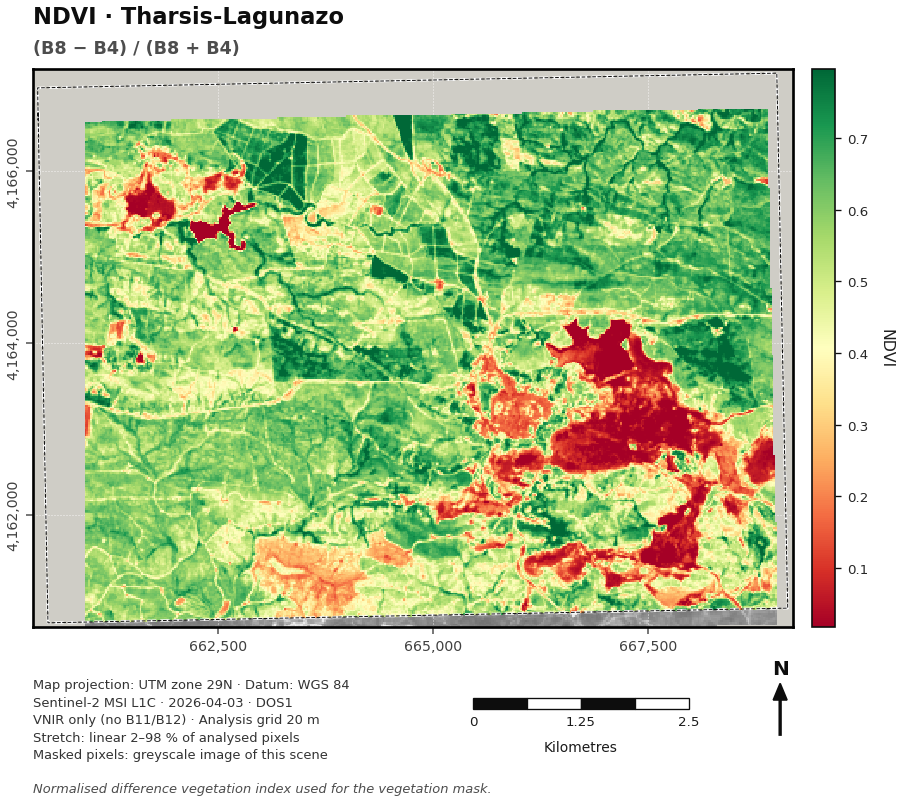

  saved  fig_00b_analysis_mask.png  +  fig_00b_analysis_mask.pdf   (400 dpi)


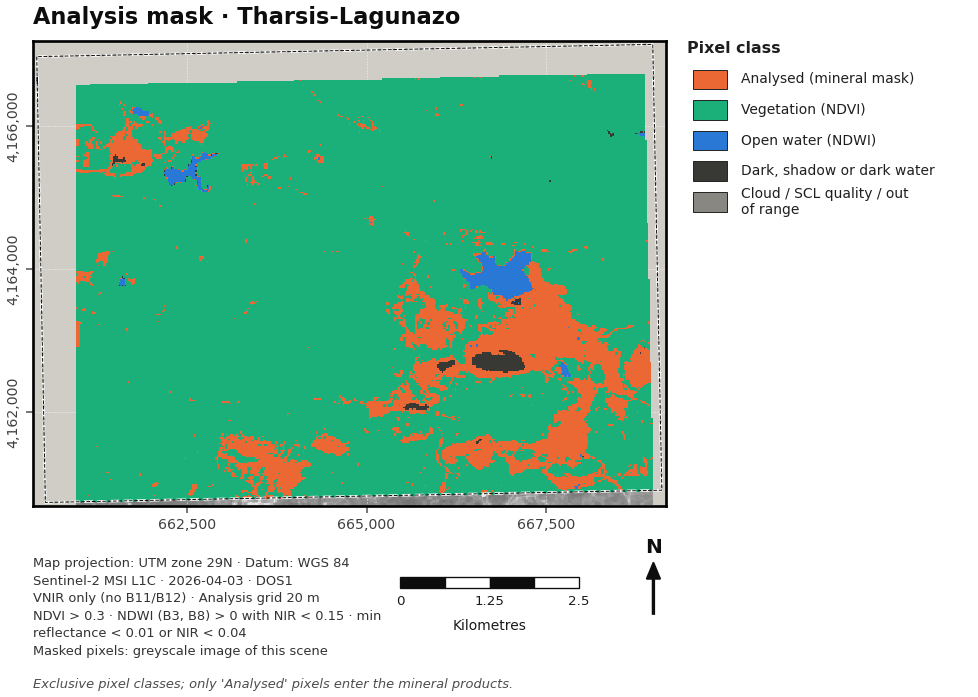

In [6]:
SCL = None
QA_BAD = np.zeros((H, W), bool); SCL_WATER = np.zeros((H, W), bool); SCL_DARK = np.zeros((H, W), bool)
if SCL_FILE:
    _scl, _ = read_to_grid(SCL_FILE, categorical=True)
    SCL = np.where(np.isfinite(_scl), _scl, 0).astype(np.int16)
    if SCL.max() > 11:
        raise ValueError(f"SCL values up to {SCL.max()} found; scene classes are 0-11. Export the SCL layer with its "
                         "class values (8-bit / 'raw' integers), not a stretched or scaled image.")
    QA_BAD = INSIDE & np.isin(SCL, list(SCL_MASK_CLASSES))
    SCL_WATER = INSIDE & (SCL == SCL_WATER_CLASS)
    SCL_DARK = INSIDE & (SCL == SCL_DARK_CLASS)
    _cnt = pd.Series(SCL[INSIDE]).value_counts().sort_index()
    print("SCL classes inside the AOI (pixels): " + ", ".join(f"{int(k)}: {int(v):,}" for k, v in _cnt.items()))

with np.errstate(divide="ignore", invalid="ignore"):
    NDVI = (R["B8"] - R["B4"]) / (R["B8"] + R["B4"])
    NDWI = (R["B3"] - R["B8"]) / (R["B3"] + R["B8"])
    if HAVE_SWIR:
        MNDWI = (R["B3"] - R["B11"]) / (R["B3"] + R["B11"])
        WATER_IDX = np.where(np.isfinite(MNDWI), MNDWI, NDWI)        # NDWI where B11 is missing (e.g. clamped 0)
        WATER_IDX_NAME = "MNDWI (B3, B11)"
    else:
        WATER_IDX, WATER_IDX_NAME = NDWI, "NDWI (B3, B8)"
NIR_FOR_WATER = R["B8A"] if "B8A" in R else R["B8"]
for _a in (NDVI, WATER_IDX):
    _a[~INSIDE] = np.nan

MIN_R = np.full((H, W), np.nan, dtype="float32")
_stack = np.stack([R[b] for b in ANALYSIS_BANDS])
with np.errstate(invalid="ignore"):
    MIN_R[INSIDE] = np.nanmin(_stack[:, INSIDE], axis=0)
del _stack

OUT_RANGE = INSIDE & ~IN_RANGE
WATER = INSIDE & ~QA_BAD & (((WATER_IDX > WATER_INDEX_THRESHOLD) & (NIR_FOR_WATER < WATER_NIR_MAX)) | SCL_WATER)
VEG   = INSIDE & (NDVI > NDVI_VEG_THRESHOLD)
DARK  = INSIDE & ((MIN_R < DARK_REFL_MIN) | (NIR_FOR_WATER < DARK_NIR_MAX) | SCL_DARK)

# exclusive class code (lowest priority first, then overwrite); -1 = outside AOI / no data
MASK_CODE = np.full((H, W), -1, dtype=np.int16)
MASK_CODE[INSIDE] = 0
MASK_CODE[DARK] = 3
MASK_CODE[VEG] = 1
MASK_CODE[OUT_RANGE] = 4
MASK_CODE[WATER] = 2
MASK_CODE[QA_BAD] = 4
MASK_NAMES  = ["Analysed (mineral mask)", "Vegetation (NDVI)", f"Open water ({WATER_IDX_NAME.split()[0]})",
               "Dark, shadow or dark water", "Cloud / SCL quality / out of range"]
MASK_COLORS = ["#eb6834", "#1baf7a", "#2a78d6", "#383835", "#898781"]

MASK_MIN = MASK_CODE == 0
if MASK_MIN.sum() < 100:
    raise RuntimeError(f"Only {int(MASK_MIN.sum())} pixels pass the mineral mask - check the AOI, the scaling (§3) and "
                       "the NDVI / water / DARK_REFL_MIN thresholds before continuing.")
BASE_NOVEG = INSIDE & ~QA_BAD & ~OUT_RANGE & ~WATER & ~DARK          # used by the NDVI sensitivity test

def mineral_layer(arr, mask=None):
    """Copy of a 2-D product with NaN outside the mineral mask."""
    out = np.array(arr, dtype="float32", copy=True)
    out[~(MASK_MIN if mask is None else mask)] = np.nan
    return out

mask_rows = []
n_in = int(INSIDE.sum())
for k, name in enumerate(MASK_NAMES):
    n = int((MASK_CODE == k).sum())
    mask_rows.append({"class": name, "pixels": n, "area_km2": round(n * PIXEL_AREA_KM2, 3),
                      "percent_of_AOI": round(100 * n / max(n_in, 1), 1)})
MASK_TABLE = pd.DataFrame(mask_rows)
MASK_TABLE.to_csv(TABLE_DIR / "tab_01_mask_summary.csv", index=False, encoding="utf-8-sig")
print(MASK_TABLE.to_string(index=False))
if MASK_MIN.sum() < 0.15 * n_in:
    print(f"\nNOTE: only {100 * MASK_MIN.sum() / max(n_in, 1):.1f} % of the AOI is analysed. Results are restricted to bare "
          "surfaces in this scene; compare with a late-summer scene before generalising.")

fig = plot_single_band(NDVI, f"NDVI · {SITE_NAME}\n(B8 − B4) / (B8 + B4)", "NDVI", cmap="RdYlGn", fname="fig_00_ndvi",
                       caption="Normalised difference vegetation index used for the vegetation mask.")
plt.show()
fig = plot_categorical(MASK_CODE, f"Analysis mask · {SITE_NAME}", MASK_COLORS, MASK_NAMES,
                       fname="fig_00b_analysis_mask", key_title="Pixel class",
                       extra=[f"NDVI > {NDVI_VEG_THRESHOLD:g} · {WATER_IDX_NAME} > {WATER_INDEX_THRESHOLD:g} with NIR < "
                              f"{WATER_NIR_MAX:g} · min reflectance < {DARK_REFL_MIN:g} or NIR < {DARK_NIR_MAX:g}"],
                       caption="Exclusive pixel classes; only 'Analysed' pixels enter the mineral products.")
plt.show()

## 5 · Colour composites

* **Natural colour (4-3-2)** for geographic context. For L1C, check it for cloud, haze and shadow.
* **Colour infrared (8-4-3)**: vegetation appears red, bare waste in cyan-grey to white tones.
* **SWIR composite (12-11-2)**, if SWIR is present: bare waste units separate more clearly. Hues depend on
  mineralogy, moisture and grain size, so interpret them only together with the index maps.

  saved  fig_01_natural_colour.png  +  fig_01_natural_colour.pdf   (400 dpi)


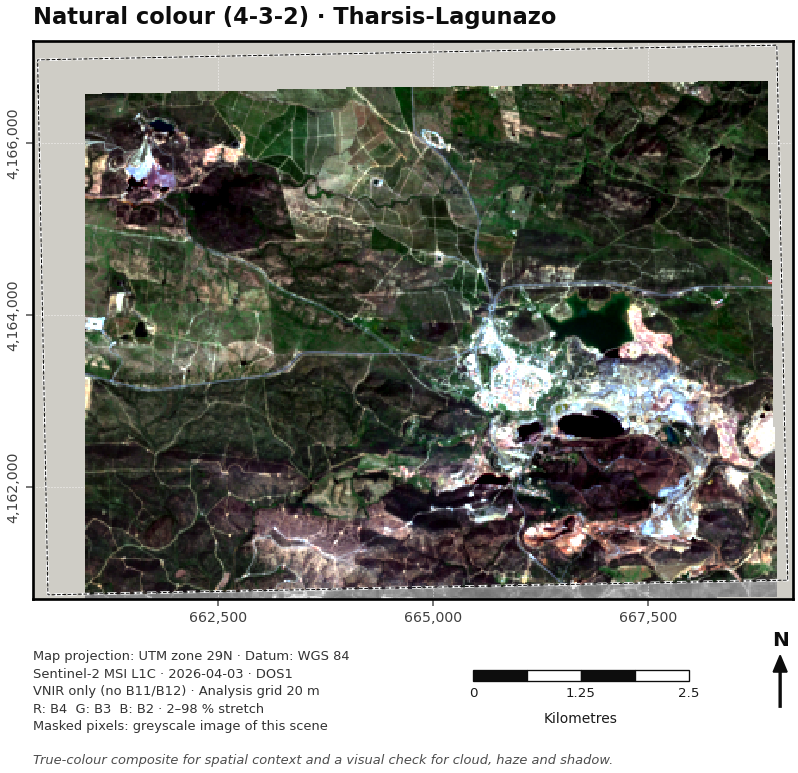

  saved  fig_02_colour_infrared.png  +  fig_02_colour_infrared.pdf   (400 dpi)


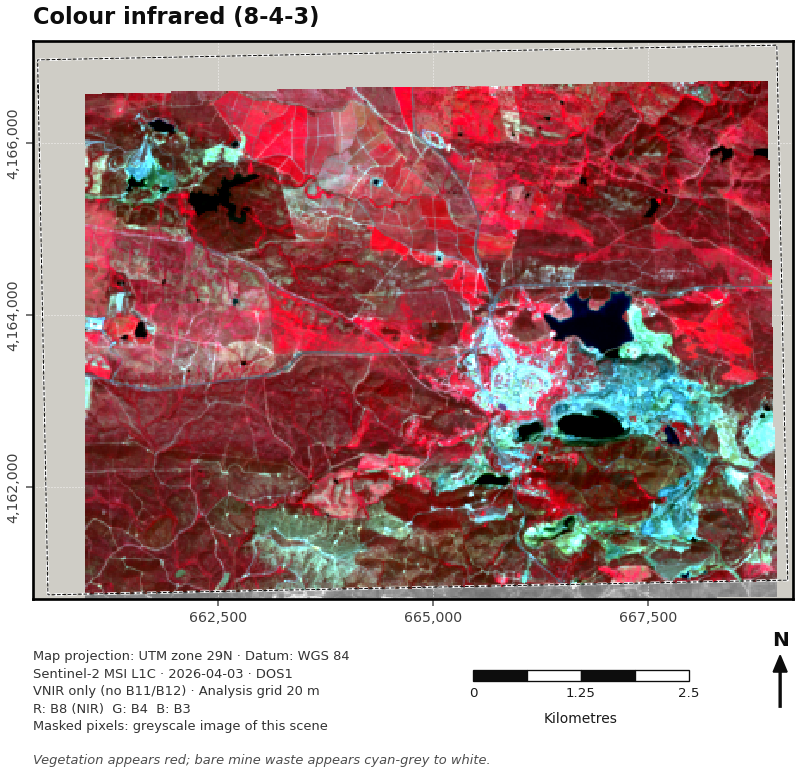

SWIR composite skipped: B11/B12 not loaded.


In [ ]:
def _ctx(arr):
    out = np.array(arr, dtype="float32", copy=True); out[~INSIDE] = np.nan
    return out

fig = plot_rgb(make_rgb(_ctx(R["B4"]), _ctx(R["B3"]), _ctx(R["B2"])), f"Natural colour (4-3-2) · {SITE_NAME}",
               subtitle="R: B4  G: B3  B: B2 · 2-98 % stretch", fname="fig_01_natural_colour",
               caption="True-colour composite for spatial context and a visual check for cloud, haze and shadow.")
plt.show()
fig = plot_rgb(make_rgb(_ctx(R["B8"]), _ctx(R["B4"]), _ctx(R["B3"])), "Colour infrared (8-4-3)",
               subtitle="R: B8 (NIR)  G: B4  B: B3", fname="fig_02_colour_infrared",
               caption="Vegetation appears red; bare mine waste appears cyan-grey to white.")
plt.show()
if HAVE_SWIR:
    fig = plot_rgb(make_rgb(_ctx(R["B12"]), _ctx(R["B11"]), _ctx(R["B2"])), "SWIR composite (12-11-2)",
                   subtitle="R: B12 (SWIR-2)  G: B11 (SWIR-1)  B: B2", fname="fig_03_swir_composite",
                   caption="SWIR composite; interpret hues only together with the index maps.")
    plt.show()
else:
    print("SWIR composite skipped: B11/B12 not loaded.")

## 6 · Spectral indices

Ratios suppress albedo and topographic shading (Sabins, 1999). For each index the table gives the formula, the
physical basis, other surfaces that raise it, the label used in the literature and the mode it needs. High values
flag the target. Band centres are those of the platform printed in §3.

| Index (key) | Sentinel-2 formula | Physical basis | Also raised by | Literature label | Needs |
|---|---|---|---|---|---|
| Fe³⁺ charge transfer (`Fe3_B4B2`) | B4 / B2 | Fe³⁺ charge-transfer absorption below ~0.55 µm lowers blue against red | red soils, dry vegetation; L1C haze in B2, which DOS1 only partly removes | TM 3/1 "iron oxides" (Sabins, 1999); S2 4/2 (van der Werff & van der Meer, 2016) | VNIR |
| Fe³⁺, blue-free (`Fe3_B4B3`) | B4 / B3 | the same absorption edge, measured with green instead of blue | as above, less sensitive to haze | S2 4/3 "ferric iron" (van der Meer et al., 2014) | VNIR |
| Fe³⁺ crystal field (`FeCF_B6B8A`) | B6 / B8A | reflectance maximum near 0.74 µm against the Fe³⁺ crystal-field absorption at ~0.86–0.94 µm (nearer 0.86 µm for hematite, nearer 0.92 µm for goethite and jarosite) | anything with low NIR relative to the red edge (wet or dark surfaces); **strongly and inversely tied to vegetation** | S2 6/8A "hematite + jarosite" (Ge et al., 2020) | VNIR (B6, B8A) |
| NIR Fe³⁺ depth (`FeCF_depthB8A`) | 1 − B8A / [B6 + (B11 − B6)·(λ8A − λ6)/(λ11 − λ6)] | depth of the crystal-field band at B8A below a straight B6–B11 continuum | as above | simple band-depth analogue of Fe-feature fitting with Sentinel-2 (van der Werff & van der Meer, 2015) | SWIR |
| SWIR1 / NIR (`SWIR1_NIR_B11B8A`) | B11 / B8A | low NIR against SWIR1: the Fe³⁺ crystal-field band and no NIR vegetation plateau | moisture, dark waste | S2 11/8 "ferric oxides" (van der Meer et al., 2014). B8A is used for its native 20 m and its match to OLI B5 | SWIR |
| Gossan (`Gossan_B11B4`) | B11 / B4 | bright SWIR1 against the red band | bare soils | S2 11/4 "gossan" (van der Meer et al., 2014) | SWIR |
| OH/SO₄ ± NPV (`OH_SO4_B11B12`) | B11 / B12 | absorptions inside B12 (~2.10–2.28 µm): Al-OH clays and micas, alunite, jarosite (~2.26 µm), gypsum | dry plant material (lignocellulose near 2.1 and 2.3 µm); green vegetation (leaf water); moisture | TM 5/7 "hydroxyl-bearing alteration"; S2 11/12 (van der Werff & van der Meer, 2016) | SWIR |

Caveats to state in the thesis:

* **B11/B12 cannot separate** clay/mica from jarosite, alunite, gypsum or dry vegetation (Hively et al., 2021).
  Features near 2.33 µm (chlorite, carbonate), which EnMAP resolves, fall largely outside B12.
* B6/B8A and the NIR depth are **not** vegetation-free. Pixels just below the NDVI threshold still carry the
  vegetation red edge, and §12 tests each index against NDVI.
* r3's red-edge ratios B6/B7 ("Al-OH clay") and B6/B5 ("ferrous iron") are not used: neither wavelength pair
  contains an Al-OH or Fe²⁺ absorption. The "ferrous iron" index of van der Meer et al. (2014), B12/B8 + B3/B4, is
  not added either: half of it is the reciprocal of B4/B3, so it largely mirrors the ferric index.

In [ ]:
def safe_ratio(num, den, min_den=DARK_REFL_MIN):
    """num/den with NaN where the denominator is below min_den or the result is not finite."""
    with np.errstate(divide="ignore", invalid="ignore"):
        r = np.asarray(num / den, dtype="float32")
        r[~np.isfinite(r) | ~(den >= min_den)] = np.nan
    return r

RAW_IDX, IDX_LABEL, IDX_FORMULA = {}, {}, {}
def _add_index(key, arr, label, formula):
    RAW_IDX[key], IDX_LABEL[key], IDX_FORMULA[key] = arr, label, formula

NIR_N = "B8A" if "B8A" in R else "B8"
_add_index("Fe3_B4B2", safe_ratio(R["B4"], R["B2"]), "Fe³⁺ B4/B2", "B4 / B2")
_add_index("Fe3_B4B3", safe_ratio(R["B4"], R["B3"]), "Fe³⁺ B4/B3 (blue-free)", "B4 / B3")
if HAVE_B6B8A:
    _add_index("FeCF_B6B8A", safe_ratio(R["B6"], R["B8A"]), "Fe³⁺ crystal field B6/B8A", "B6 / B8A")
if HAVE_SWIR and HAVE_B6B8A:
    with np.errstate(divide="ignore", invalid="ignore"):
        _cont = R["B6"] + (R["B11"] - R["B6"]) * (WL["B8A"] - WL["B6"]) / (WL["B11"] - WL["B6"])
        _depth = (1.0 - R["B8A"] / _cont).astype("float32")
    _depth[~np.isfinite(_depth) | ~(_cont >= DARK_REFL_MIN)] = np.nan
    _add_index("FeCF_depthB8A", _depth, "NIR Fe³⁺ depth (B8A)", "1 - B8A / continuum(B6-B11)")
if HAVE_SWIR:
    _add_index("SWIR1_NIR_B11B8A", safe_ratio(R["B11"], R[NIR_N]), f"SWIR1/NIR B11/{NIR_N}", f"B11 / {NIR_N}")
    _add_index("Gossan_B11B4", safe_ratio(R["B11"], R["B4"]), "Gossan B11/B4", "B11 / B4")
    _add_index("OH_SO4_B11B12", safe_ratio(R["B11"], R["B12"]), "OH/SO₄ ± NPV B11/B12", "B11 / B12")
IDX = {k: mineral_layer(v) for k, v in RAW_IDX.items()}

def describe(arr):
    v = arr[np.isfinite(arr)]
    if v.size == 0:
        return {"pixels": 0}
    p = np.percentile(v, [2, 25, 50, 75, 98])
    return {"pixels": int(v.size), "min": v.min(), "p2": p[0], "q1": p[1], "median": p[2], "q3": p[3],
            "p98": p[4], "max": v.max(), "mean": v.mean(), "sd": v.std()}

INDEX_TABLE = pd.DataFrame([{"index": IDX_LABEL[k], "formula": IDX_FORMULA[k], **describe(a)} for k, a in IDX.items()])
INDEX_TABLE.to_csv(TABLE_DIR / "tab_02_index_statistics.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
print(f"Indices computed ({MODE_LABEL}): {', '.join(IDX)}")
print("Statistics over analysed pixels only:")
print(INDEX_TABLE.drop(columns="formula").round(3).to_string(index=False))

Indices computed (VNIR only (no B11/B12)): Fe3_B4B2, Fe3_B4B3, FeCF_B6B8A
Statistics over analysed pixels only:
                    index  pixels   min    p2    q1  median    q3   p98   max  mean    sd
               Fe³⁺ B4/B2   14085 0.732 1.350 1.787   2.018 2.212 2.737 3.503 2.010 0.328
   Fe³⁺ B4/B3 (blue-free)   14085 0.638 1.153 1.314   1.434 1.535 1.814 2.253 1.435 0.165
Fe³⁺ crystal field B6/B8A   14085 0.631 0.778 0.857   0.918 0.994 1.103 1.257 0.926 0.086


  saved  fig_04_index_Fe3_B4B2.png  +  fig_04_index_Fe3_B4B2.pdf   (400 dpi)


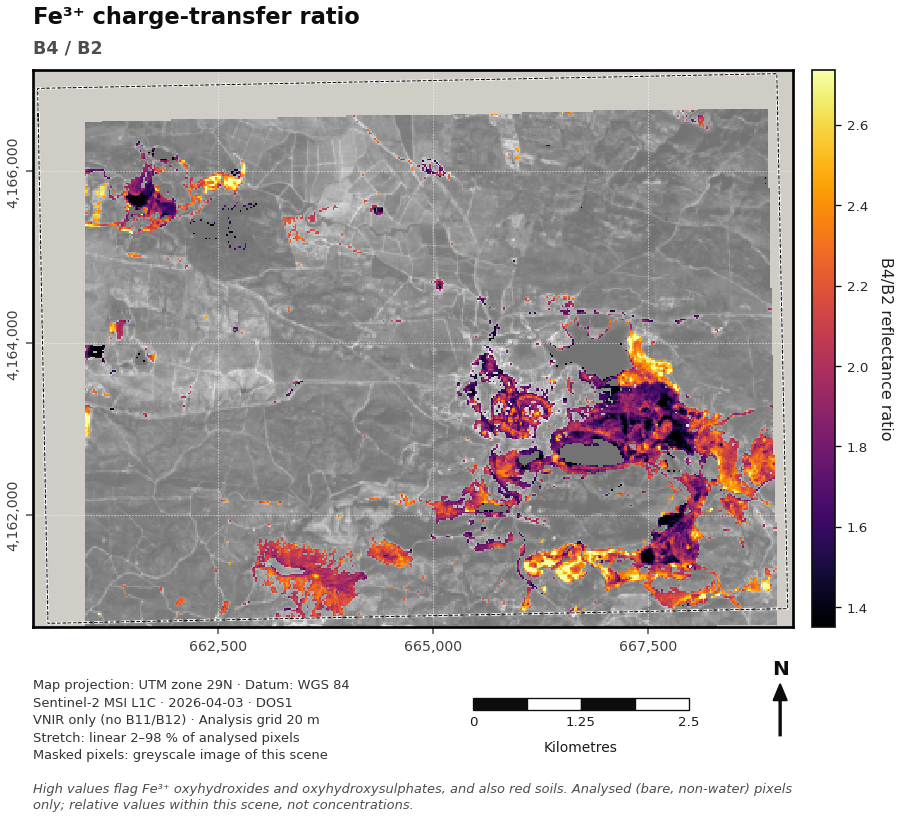

  saved  fig_05_index_FeCF_B6B8A.png  +  fig_05_index_FeCF_B6B8A.pdf   (400 dpi)


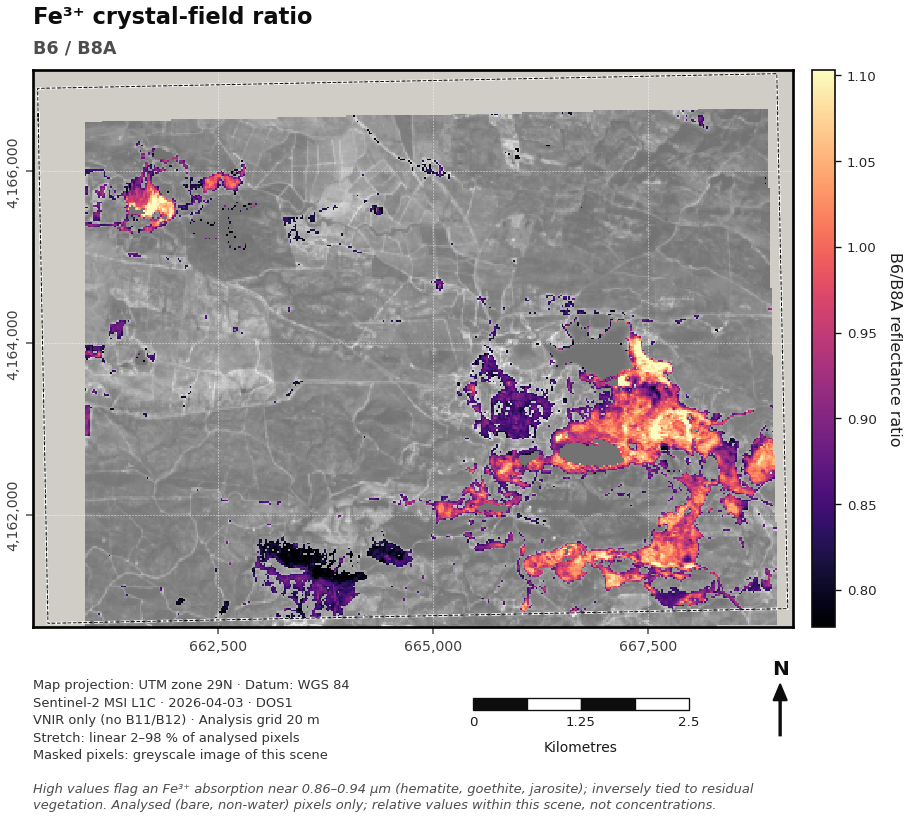

  saved  fig_08_supplementary_indices.png  +  fig_08_supplementary_indices.pdf   (400 dpi)


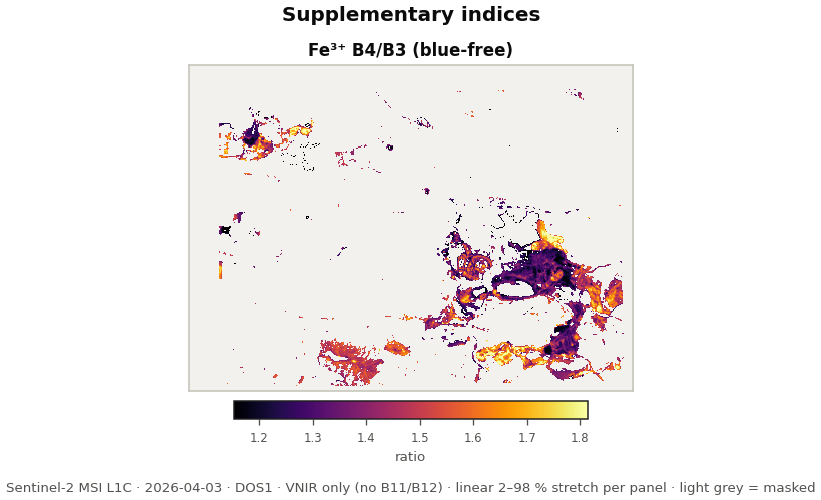

  saved  fig_09_index_distributions.png  +  fig_09_index_distributions.pdf   (400 dpi)


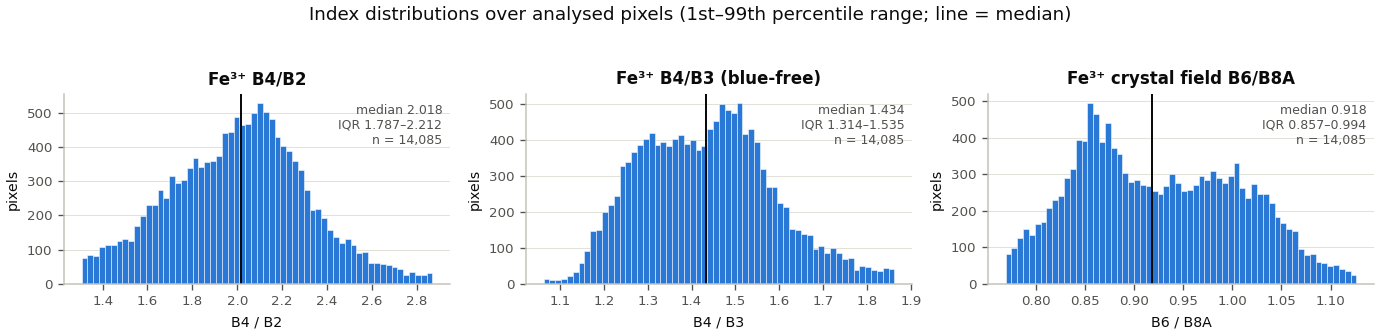

In [ ]:
_cap_rel = "Analysed (bare, non-water) pixels only; relative values within this scene, not concentrations."
fig = plot_single_band(IDX["Fe3_B4B2"], "Fe³⁺ charge-transfer ratio\nB4 / B2", "B4/B2 reflectance ratio",
                       cmap="inferno", fname="fig_04_index_Fe3_B4B2",
                       caption="High values flag Fe³⁺ oxyhydroxides and oxyhydroxysulphates, and also red soils. " + _cap_rel)
plt.show()
if "FeCF_B6B8A" in IDX:
    fig = plot_single_band(IDX["FeCF_B6B8A"], "Fe³⁺ crystal-field ratio\nB6 / B8A", "B6/B8A reflectance ratio",
                           cmap="magma", fname="fig_05_index_FeCF_B6B8A",
                           caption="High values flag an Fe³⁺ absorption near 0.86-0.94 µm (hematite, goethite, jarosite); "
                                   "inversely tied to residual vegetation. " + _cap_rel)
    plt.show()
if HAVE_SWIR:
    fig = plot_single_band(IDX["OH_SO4_B11B12"], "OH/SO₄ ratio\nB11 / B12", "B11/B12 reflectance ratio", cmap="viridis",
                           fname="fig_06_index_OH_SO4_B11B12",
                           caption="High values flag absorptions inside B12: Al-OH clays and micas, alunite, jarosite, gypsum, "
                                   "and dry plant material. " + _cap_rel)
    plt.show()
    fig = plot_single_band(IDX["SWIR1_NIR_B11B8A"], f"SWIR1/NIR ratio\nB11 / {NIR_N}", f"B11/{NIR_N} reflectance ratio",
                           cmap="cividis", fname="fig_07_index_SWIR1_NIR",
                           caption="'Ferric oxides' in the Sentinel-2 index set; also raised by moisture and dark waste. " + _cap_rel)
    plt.show()
_supp = [k for k in ("Fe3_B4B3", "FeCF_depthB8A", "Gossan_B11B4") if k in IDX]
fig = panel_maps([IDX[k] for k in _supp], [IDX_LABEL[k] for k in _supp], ["inferno"] * len(_supp),
                 "Supplementary indices", fname="fig_08_supplementary_indices",
                 cbar_labels=["depth (unitless)" if k == "FeCF_depthB8A" else "ratio" for k in _supp])
plt.show()

# distributions: one panel per index, each on its own axis (values are not comparable across indices)
keys = list(IDX); ncol = min(3, len(keys)); nrow = int(math.ceil(len(keys) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.9 * ncol, 2.9 * nrow), squeeze=False)
for ax, k in zip(axes.ravel(), keys):
    v = IDX[k][np.isfinite(IDX[k])]
    lo_, hi_ = np.percentile(v, [1, 99])
    ax.hist(v, bins=60, range=(lo_, hi_), color=SERIES[0], edgecolor="white", linewidth=0.3)
    med, q1, q3 = np.percentile(v, [50, 25, 75])
    ax.axvline(med, color=INK, lw=1.2)
    ax.set_title(IDX_LABEL[k], fontsize=10)
    ax.text(0.98, 0.95, f"median {med:.3f}\nIQR {q1:.3f}–{q3:.3f}\nn = {v.size:,}", transform=ax.transAxes,
            ha="right", va="top", fontsize=7.5, color=INK_2)
    ax.set_xlabel(IDX_FORMULA[k], fontsize=8.5); ax.set_ylabel("pixels", fontsize=8.5)
    style_chart(ax)
for ax in axes.ravel()[len(keys):]:
    ax.axis("off")
fig.suptitle("Index distributions over analysed pixels (1st-99th percentile range; line = median)", fontsize=11, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_fig(fig, "fig_09_index_distributions")
plt.show()

## 7 · Ratio-RGB composite

* **VNIR + SWIR**: R = Fe³⁺ (B4/B2), G = OH/SO₄ (B11/B12), B = SWIR1/NIR (B11/B8A). Red–magenta is
  Fe³⁺-dominant, green is OH/SO₄-dominant and yellow shows both.
* **VNIR only**: R = Fe³⁺ charge transfer (B4/B2), G = Fe³⁺ crystal field (B6/B8A), B = B4/B3. R and B are
  strongly correlated, so magenta means charge-transfer-dominant, green crystal-field-dominant and light tones
  both.

Each channel is stretched 2–98 % over the mineral mask. Colours are relative *within this mask*, not absolute
mineral classes.

  saved  fig_10_ratio_rgb.png  +  fig_10_ratio_rgb.pdf   (400 dpi)


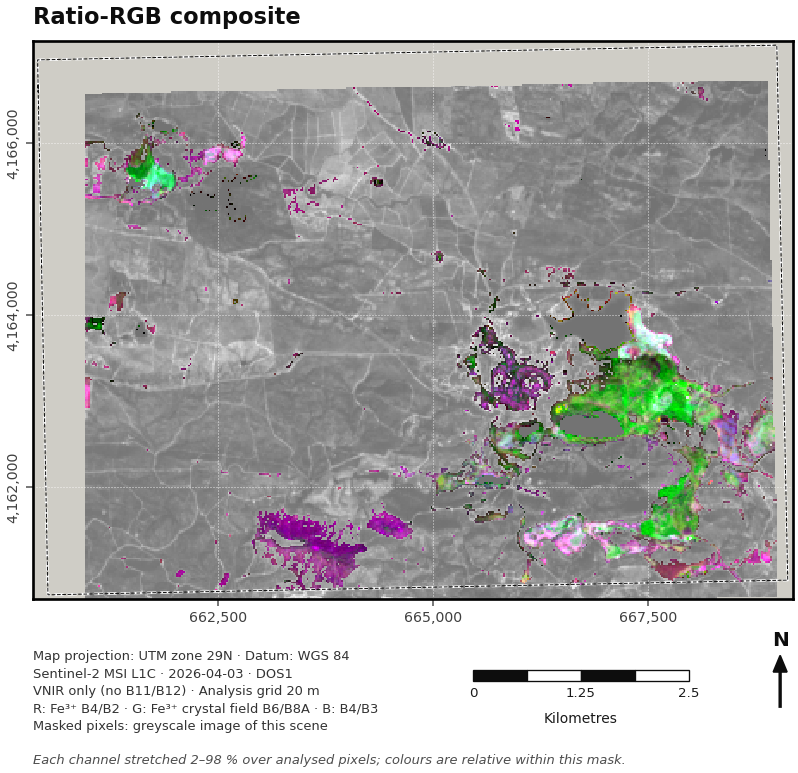

In [10]:
if HAVE_SWIR:
    comp = make_rgb(IDX["Fe3_B4B2"], IDX["OH_SO4_B11B12"], IDX["SWIR1_NIR_B11B8A"])
    _sub = f"R: Fe³⁺ B4/B2 · G: OH/SO₄ B11/B12 · B: SWIR1/NIR B11/{NIR_N}"
elif "FeCF_B6B8A" in IDX:
    comp = make_rgb(IDX["Fe3_B4B2"], IDX["FeCF_B6B8A"], IDX["Fe3_B4B3"])
    _sub = "R: Fe³⁺ B4/B2 · G: Fe³⁺ crystal field B6/B8A · B: B4/B3"
else:
    comp = None
    print("Ratio-RGB skipped: needs B11/B12 or B6/B8A.")
if comp is not None:
    comp[~MASK_MIN] = np.nan
    fig = plot_rgb(comp, "Ratio-RGB composite", subtitle=_sub, fname="fig_10_ratio_rgb",
                   caption="Each channel stretched 2–98 % over analysed pixels; colours are relative within this mask.")
    plt.show()

## 8 · Crósta technique: feature-oriented principal-component selection

PCA is run on a four-band subset over the mineral mask. The component whose **two diagnostic loadings have opposite
signs and are both strong** is selected, then oriented so the target is bright (Crósta & Moore, 1989;
Loughlin, 1991).

| Target | VNIR + SWIR subset | VNIR-only subset | Diagnostic pair | Oriented by |
|---|---|---|---|---|
| Iron oxides | B2, B4, B8A, B11 (TM 1-3-4-5 analogue) | B2, B4, B6, B8A (B6 replaces SWIR-1; an adaptation, not a literature subset) | B2 / B4 | B4 > 0 |
| Iron oxides, blue-free check | B3, B4, B8A, B11 | B3, B4, B6, B8A | B3 / B4 | B4 > 0 |
| Hydroxyls | B2, B8A, B11, B12 (TM 1-4-5-7 analogue) | not possible | B11 / B12 | B11 > 0 |

Selection score = |l₁ · l₂|, so a component dominated by one band scores low. A warning is printed when the weaker
diagnostic loading is below 0.25 or the component explains < 1 % of the variance. Always read the loadings;
`CROSTA_FE_PC` / `CROSTA_OH_PC` in CONFIG force a component. The Spearman correlation with the matching ratio is a
quick sanity check.

In [11]:
def crosta_fpcs(bands, diag_pair, ref_band, label, standardise=None, force_pc=None, verbose=True):
    standardise = CROSTA_STANDARDISE if standardise is None else standardise
    ok = MASK_MIN.copy()
    for b in bands:
        ok &= np.isfinite(R[b])
    flat = np.stack([R[b][ok] for b in bands], axis=-1).astype("float64")
    X = StandardScaler().fit_transform(flat) if standardise else flat - flat.mean(axis=0)
    pca = PCA().fit(X)
    comps, scores, var = pca.components_, pca.transform(X), pca.explained_variance_ratio_
    i1, i2, iref = bands.index(diag_pair[0]), bands.index(diag_pair[1]), bands.index(ref_band)
    cand = []
    for pc in range(1, len(bands)):                               # PC1 = albedo, excluded
        l1, l2 = comps[pc, i1], comps[pc, i2]
        if l1 * l2 < 0:
            cand.append((abs(l1 * l2), abs(l1) + abs(l2), pc))
    if force_pc:
        best, rule = int(force_pc) - 1, "forced in CONFIG"
    elif cand:
        best, rule = max(cand)[2], "automatic"
    else:
        best, rule = len(bands) - 1, "fallback: no opposite-sign component"
    sc = scores[:, best].copy()
    flipped = comps[best, iref] < 0
    if flipped:
        sc = -sc
    img = np.full((H, W), np.nan, dtype="float32"); img[ok] = sc
    load = comps[best] * (-1 if flipped else 1)
    strength = min(abs(load[i1]), abs(load[i2]))
    if verbose:
        print(f"\n=== Crósta FPCS: {label} | bands {'-'.join(bands)} | "
              f"{'correlation' if standardise else 'covariance'} matrix ===")
        hdr = "PC   " + "".join(f" {b:>5}" for b in bands) + "   %var"
        print(hdr); print("-" * len(hdr))
        for pc in range(len(bands)):
            row = "".join(f" {comps[pc, j]:+5.2f}" for j in range(len(bands)))
            print(f"PC{pc+1} {row}  {100*var[pc]:5.1f}" + ("   <== selected" if pc == best else ""))
        print(f"Selected PC{best+1} ({rule}); oriented so {ref_band} is positive"
              f"{' (sign flipped)' if flipped else ''}; diagnostic strength min|l| = {strength:.2f}")
        if strength < 0.25:
            print("  WARNING: weak diagnostic loadings - check whether another component isolates the target.")
        if var[best] < 0.01:
            print(f"  NOTE: PC{best+1} explains {100*var[best]:.2f} % of the variance - inspect the map for noise.")
    return {"image": img, "pc": best, "loadings": load, "var": var[best], "rule": rule, "strength": strength,
            "standardised": standardise, "bands": bands}

def spearman_layers(a, b, mask=None, max_n=50000, seed=0):
    m = np.isfinite(a) & np.isfinite(b)
    if mask is not None:
        m &= mask
    idx = np.flatnonzero(m)
    if idx.size > max_n:
        idx = np.random.default_rng(seed).choice(idx, max_n, replace=False)
    if idx.size < 10:
        return np.nan, int(idx.size)
    return float(stats.spearmanr(a.ravel()[idx], b.ravel()[idx])[0]), int(idx.size)

if HAVE_SWIR:
    CROSTA_SETS = {"FE": ([ "B2", "B4", NIR_N, "B11"], ("B2", "B4"), "B4", "iron oxides"),
                   "FE3": (["B3", "B4", NIR_N, "B11"], ("B3", "B4"), "B4", "iron oxides, blue-free check"),
                   "OH": (["B2", NIR_N, "B11", "B12"], ("B11", "B12"), "B11", "hydroxyls")}
elif HAVE_B6B8A:
    CROSTA_SETS = {"FE": (["B2", "B4", "B6", "B8A"], ("B2", "B4"), "B4", "iron oxides (VNIR adaptation)"),
                   "FE3": (["B3", "B4", "B6", "B8A"], ("B3", "B4"), "B4", "iron oxides, blue-free check (VNIR)")}
else:
    CROSTA_SETS = {"FE": (["B2", "B3", "B4", "B8"], ("B2", "B4"), "B4", "iron oxides (10 m bands only)")}

CR_FE = crosta_fpcs(*CROSTA_SETS["FE"], force_pc=CROSTA_FE_PC)
CR_FE3 = crosta_fpcs(*CROSTA_SETS["FE3"]) if "FE3" in CROSTA_SETS else None
CR_OH = crosta_fpcs(*CROSTA_SETS["OH"], force_pc=CROSTA_OH_PC) if "OH" in CROSTA_SETS else None

_rows = [{"component": f"Crósta Fe ({'-'.join(CR_FE['bands'])})", "selected_PC": CR_FE["pc"] + 1,
          "variance_pct": 100 * CR_FE["var"], "min_diag_loading": CR_FE["strength"], "spearman_vs": "B4/B2",
          "rho": spearman_layers(CR_FE["image"], IDX["Fe3_B4B2"])[0]}]
if CR_FE3 is not None:
    _rows.append({"component": f"Crósta Fe blue-free ({'-'.join(CR_FE3['bands'])})", "selected_PC": CR_FE3["pc"] + 1,
                  "variance_pct": 100 * CR_FE3["var"], "min_diag_loading": CR_FE3["strength"], "spearman_vs": "B4/B3",
                  "rho": spearman_layers(CR_FE3["image"], IDX["Fe3_B4B3"])[0]})
if CR_OH is not None:
    _rows.append({"component": f"Crósta OH ({'-'.join(CR_OH['bands'])})", "selected_PC": CR_OH["pc"] + 1,
                  "variance_pct": 100 * CR_OH["var"], "min_diag_loading": CR_OH["strength"], "spearman_vs": "B11/B12",
                  "rho": spearman_layers(CR_OH["image"], IDX["OH_SO4_B11B12"])[0]})
CROSTA_TABLE = pd.DataFrame(_rows)
CROSTA_TABLE.to_csv(TABLE_DIR / "tab_03_crosta_selection.csv", index=False, float_format="%.3f", encoding="utf-8-sig")
print("\n" + CROSTA_TABLE.round(3).to_string(index=False))
for _, r_ in CROSTA_TABLE.iterrows():
    if np.isfinite(r_["rho"]) and r_["rho"] < 0.5:
        print(f"  CHECK: {r_['component']} correlates weakly with {r_['spearman_vs']} (rho = {r_['rho']:.2f}).")


=== Crósta FPCS: iron oxides (VNIR adaptation) | bands B2-B4-B6-B8A | correlation matrix ===
PC       B2    B4    B6   B8A   %var
------------------------------------
PC1  +0.45 +0.53 +0.53 +0.49   82.0
PC2  +0.73 +0.23 -0.33 -0.55   14.7
PC3  -0.50 +0.69 +0.19 -0.49    3.0   <== selected
PC4  +0.13 -0.44 +0.76 -0.46    0.3
Selected PC3 (automatic); oriented so B4 is positive; diagnostic strength min|l| = 0.50

=== Crósta FPCS: iron oxides, blue-free check (VNIR) | bands B3-B4-B6-B8A | correlation matrix ===
PC       B3    B4    B6   B8A   %var
------------------------------------
PC1  +0.48 +0.51 +0.52 +0.48   86.1
PC2  -0.62 -0.34 +0.32 +0.63   11.7
PC3  -0.59 +0.61 +0.33 -0.41    2.0   <== selected
PC4  +0.20 -0.50 +0.72 -0.44    0.3
Selected PC3 (automatic); oriented so B4 is positive; diagnostic strength min|l| = 0.59

                         component  selected_PC  variance_pct  min_diag_loading spearman_vs   rho
          Crósta Fe (B2-B4-B6-B8A)            3         3.025    

  saved  fig_11_crosta_iron_oxide.png  +  fig_11_crosta_iron_oxide.pdf   (400 dpi)


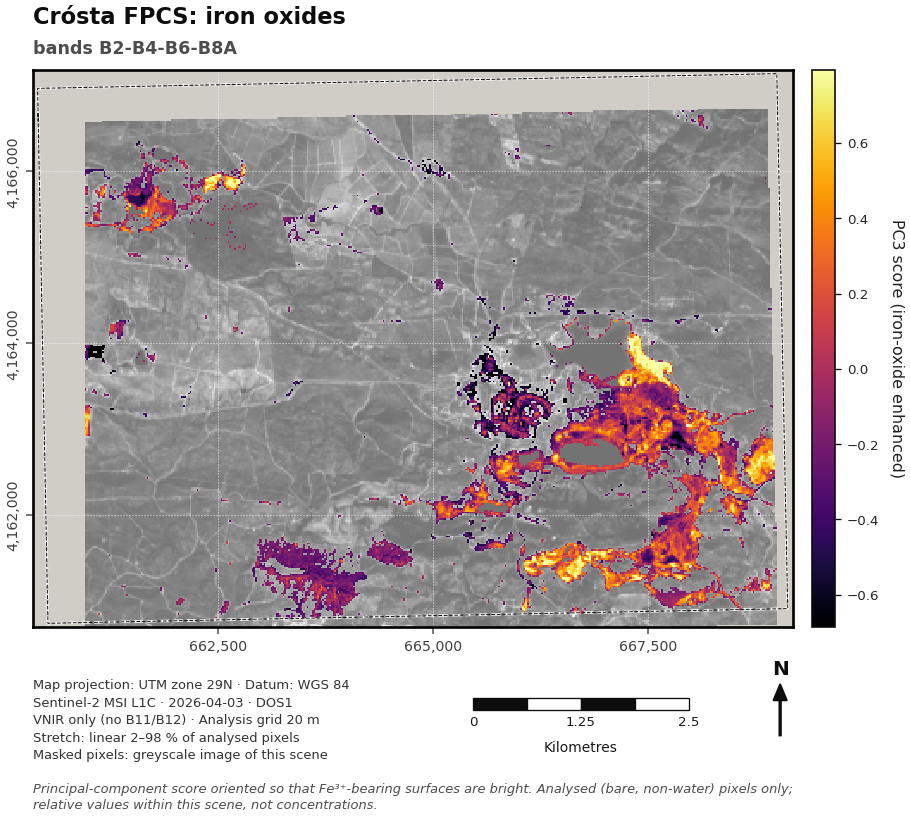

In [12]:
fig = plot_single_band(CR_FE["image"], f"Crósta FPCS: iron oxides\nbands {'-'.join(CR_FE['bands'])}",
                       f"PC{CR_FE['pc']+1} score (iron-oxide enhanced)", cmap="inferno", fname="fig_11_crosta_iron_oxide",
                       caption="Principal-component score oriented so that Fe³⁺-bearing surfaces are bright. " + _cap_rel)
plt.show()
if CR_OH is not None:
    fig = plot_single_band(CR_OH["image"], f"Crósta FPCS: hydroxyls\nbands {'-'.join(CR_OH['bands'])}",
                           f"PC{CR_OH['pc']+1} score (hydroxyl enhanced)", cmap="viridis", fname="fig_12_crosta_hydroxyl",
                           caption="Principal-component score oriented so that OH/SO₄-bearing surfaces (and dry vegetation) "
                                   "are bright. " + _cap_rel)
    plt.show()

## 9 · Anomaly thresholds and the consensus overlap map

Continuous maps are turned into anomaly classes with two independent thresholding methods:

* **Mean + kσ** of each layer over the mineral mask (k = `SIGMA_LEVELS`).
* **Concentration–area (C–A) fractal model** (Cheng et al., 1994): log(area with index ≥ v) against log(v) is
  fitted with three straight segments. The two breakpoints separate background, a weak-anomaly population and a
  strong-anomaly population. It is applied to the two ratio indices.

A pixel is a **consensus anomaly** when two lines of evidence exceed their mean + kσ for the first value in
`SIGMA_LEVELS` (the last value gives the strict version):

* **Fe³⁺**: B4/B2 **and** the Crósta iron-oxide component.
* **Second layer, VNIR + SWIR**: OH/SO₄, i.e. B11/B12 **and** the Crósta hydroxyl component. Pixels anomalous in
  both are the most jarosite- or alunite-like candidates at Sentinel-2 resolution.
* **Second layer, VNIR only**: Fe³⁺ crystal field (B6/B8A). Pixels anomalous in both show both Fe³⁺ absorptions,
  which is stronger evidence for Fe³⁺ oxyhydroxides/oxyhydroxysulphates than either alone. No OH/SO₄ statement is
  possible.

All candidates remain **pending field and XRD/FTIR confirmation**.

     layer   method  threshold  pixels  area_km2  percent_of_analysed
  Fe3_B4B2 mean+1sd      2.338    1920     0.768               13.632
  Fe3_B4B2 mean+2sd      2.665     411     0.164                2.918
  Fe3_B4B2   CA_low      1.770   10787     4.315               76.585
  Fe3_B4B2  CA_high      2.144    4664     1.866               33.113
 Crosta_Fe mean+1sd      0.348    2141     0.856               15.201
 Crosta_Fe mean+2sd      0.696     463     0.185                3.287
FeCF_B6B8A mean+1sd      1.012    2608     1.043               18.516
FeCF_B6B8A mean+2sd      1.099     322     0.129                2.286
FeCF_B6B8A   CA_low      0.838   11847     4.739               84.111
FeCF_B6B8A  CA_high      1.004    3015     1.206               21.406
  saved  fig_13_ca_fractal_thresholds.png  +  fig_13_ca_fractal_thresholds.pdf   (400 dpi)


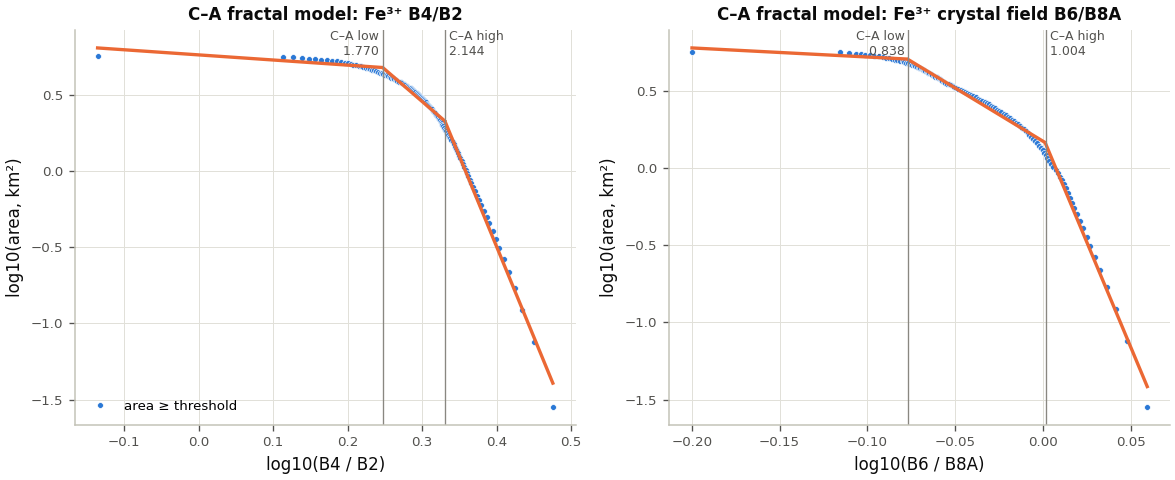

In [13]:
def sigma_thresholds(arr, levels=SIGMA_LEVELS):
    v = arr[np.isfinite(arr)]
    mu, sd = float(v.mean()), float(v.std())
    return {f"mean+{k:g}sd": mu + k * sd for k in levels}

def ca_fractal(arr, n=CA_N_THRESHOLDS, min_pts=8):
    """Three-segment piecewise-linear fit of log10(area >= v) vs log10(v). Returns (t_low, t_high, curve)."""
    v = arr[np.isfinite(arr) & (arr > 0)]
    thr = np.unique(np.quantile(v, np.linspace(0.0, 0.995, n)))
    area = np.array([(v >= t).sum() for t in thr]) * PIXEL_AREA_KM2
    x, y = np.log10(thr), np.log10(area)
    m = len(x)
    if m < 3 * min_pts:
        return np.nan, np.nan, (x, y, None)
    def sse(s, e):
        p = np.polyfit(x[s:e], y[s:e], 1)
        return float(((np.polyval(p, x[s:e]) - y[s:e]) ** 2).sum())
    best = None
    for i in range(min_pts, m - 2 * min_pts + 1):
        left = sse(0, i)
        for j in range(i + min_pts, m - min_pts + 1):
            tot = left + sse(i, j) + sse(j, m)
            if best is None or tot < best[0]:
                best = (tot, i, j)
    _, i, j = best
    return float(thr[i]), float(thr[j]), (x, y, (i, j))

LAYER_B_KEY = "OH_SO4_B11B12" if HAVE_SWIR else ("FeCF_B6B8A" if "FeCF_B6B8A" in IDX else None)
THR_LAYERS = {"Fe3_B4B2": IDX["Fe3_B4B2"], "Crosta_Fe": CR_FE["image"]}
if LAYER_B_KEY:
    THR_LAYERS[LAYER_B_KEY] = IDX[LAYER_B_KEY]
if CR_OH is not None:
    THR_LAYERS["Crosta_OH"] = CR_OH["image"]
THR = {k: sigma_thresholds(a) for k, a in THR_LAYERS.items()}
CA = {}
for key in [k for k in ("Fe3_B4B2", LAYER_B_KEY) if k]:
    t_lo, t_hi, curve = ca_fractal(IDX[key])
    CA[key] = {"CA_low": t_lo, "CA_high": t_hi, "curve": curve}
    THR[key].update({"CA_low": t_lo, "CA_high": t_hi})

thr_rows = []
for key, d in THR.items():
    for method, t in d.items():
        n = int((THR_LAYERS[key] >= t).sum()) if np.isfinite(t) else 0
        thr_rows.append({"layer": key, "method": method, "threshold": t, "pixels": n, "area_km2": n * PIXEL_AREA_KM2,
                         "percent_of_analysed": 100 * n / max(MASK_MIN.sum(), 1)})
THRESHOLD_TABLE = pd.DataFrame(thr_rows)
THRESHOLD_TABLE.to_csv(TABLE_DIR / "tab_04_anomaly_thresholds.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
print(THRESHOLD_TABLE.round(3).to_string(index=False))

fig, axes = plt.subplots(1, len(CA), figsize=(5.0 * len(CA), 4.2), squeeze=False)
for ax, key in zip(axes.ravel(), CA):
    x, y, br = CA[key]["curve"]
    ax.plot(x, y, "o", ms=3.5, color=SERIES[0], mec="white", mew=0.4, label="area ≥ threshold")
    if br is not None:
        i, j = br
        for s, e in [(0, i), (i, j), (j, len(x))]:
            p = np.polyfit(x[s:e], y[s:e], 1)
            ax.plot(x[s:e], np.polyval(p, x[s:e]), "-", lw=2, color=SERIES[1])
        for t, name, ha in [(CA[key]["CA_low"], "C–A low", "right"), (CA[key]["CA_high"], "C–A high", "left")]:
            ax.axvline(np.log10(t), color=MUTED, lw=0.8)
            ax.text(np.log10(t), ax.get_ylim()[1], f" {name} \n {t:.3f} ", va="top", ha=ha, fontsize=7.5, color=INK_2)
    ax.set_xlabel(f"log10({IDX_FORMULA[key]})"); ax.set_ylabel("log10(area, km²)")
    ax.set_title(f"C–A fractal model: {IDX_LABEL[key]}", fontsize=10)
    style_chart(ax, grid_axis="both")
axes[0, 0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
save_fig(fig, "fig_13_ca_fractal_thresholds")
plt.show()

                                   class  pixels  area_km2  percent_of_analysed
                   Background (analysed)   10873     4.349                 77.2
               Fe³⁺ charge transfer only     604     0.242                  4.3
                 Fe³⁺ crystal field only    2073     0.829                 14.7
                   Both Fe³⁺ absorptions     535     0.214                  3.8
Both Fe³⁺ absorptions (strict, mean+2sd)      18     0.007                  0.1

             evidence  pixels_a  pixels_b  pixels_both  jaccard
Fe³⁺: ratio vs Crósta      1920      2141         1139     0.39
  saved  fig_14b_individual_anomaly_layers.png  +  fig_14b_individual_anomaly_layers.pdf   (400 dpi)


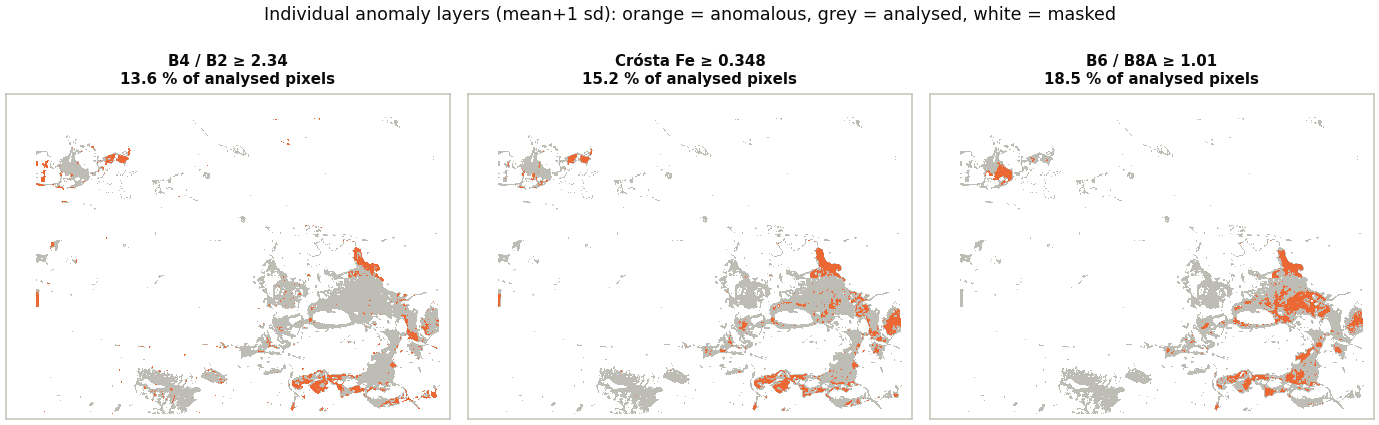

  saved  fig_14_consensus_anomaly_overlap.png  +  fig_14_consensus_anomaly_overlap.pdf   (400 dpi)


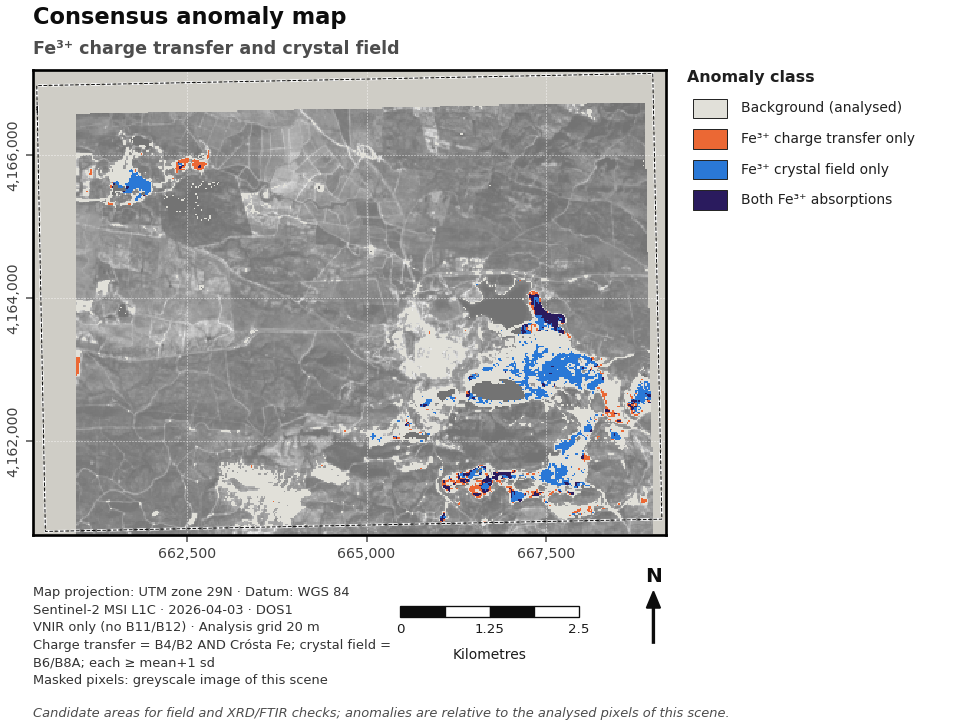

In [14]:
LVL1, LVL2 = f"mean+{SIGMA_LEVELS[0]:g}sd", f"mean+{SIGMA_LEVELS[-1]:g}sd"

def consensus(level):
    fe = MASK_MIN & (IDX["Fe3_B4B2"] >= THR["Fe3_B4B2"][level]) & (CR_FE["image"] >= THR["Crosta_Fe"][level])
    if LAYER_B_KEY is None:
        return fe, np.zeros_like(fe)
    second = MASK_MIN & (IDX[LAYER_B_KEY] >= THR[LAYER_B_KEY][level])
    if CR_OH is not None:
        second &= CR_OH["image"] >= THR["Crosta_OH"][level]
    return fe, second

FE_ANOM, B_ANOM = consensus(LVL1)
OVERLAP = np.full((H, W), -1, dtype=np.int16)
OVERLAP[MASK_MIN] = 0
OVERLAP[FE_ANOM & ~B_ANOM] = 1
OVERLAP[B_ANOM & ~FE_ANOM] = 2
OVERLAP[FE_ANOM & B_ANOM] = 3
if HAVE_SWIR:
    OVERLAP_NAMES = ["Background (analysed)", "Fe³⁺ anomaly only", "OH/SO₄ anomaly only", "Fe³⁺ + OH/SO₄ anomaly"]
    _rule = f"Fe³⁺ = B4/B2 AND Crósta Fe; OH/SO₄ = B11/B12 AND Crósta OH; each ≥ {LVL1.replace('sd', ' sd')}"
else:
    OVERLAP_NAMES = ["Background (analysed)", "Fe³⁺ charge transfer only", "Fe³⁺ crystal field only",
                     "Both Fe³⁺ absorptions"]
    _rule = f"Charge transfer = B4/B2 AND Crósta Fe; crystal field = B6/B8A; each ≥ {LVL1.replace('sd', ' sd')}"
OVERLAP_COLORS = ["#e1e0d9", "#eb6834", "#2a78d6", "#2a1b5e"]

ov_rows = []
for k, name in enumerate(OVERLAP_NAMES):
    n = int((OVERLAP == k).sum())
    ov_rows.append({"class": name, "pixels": n, "area_km2": round(n * PIXEL_AREA_KM2, 3),
                    "percent_of_analysed": round(100 * n / max(MASK_MIN.sum(), 1), 1)})
_fe2, _b2 = consensus(LVL2)
ov_rows.append({"class": f"{OVERLAP_NAMES[3]} (strict, {LVL2})", "pixels": int((_fe2 & _b2).sum()),
                "area_km2": round((_fe2 & _b2).sum() * PIXEL_AREA_KM2, 3),
                "percent_of_analysed": round(100 * (_fe2 & _b2).sum() / max(MASK_MIN.sum(), 1), 1)})
OVERLAP_TABLE = pd.DataFrame(ov_rows)
OVERLAP_TABLE.to_csv(TABLE_DIR / "tab_05_overlap_classes.csv", index=False, encoding="utf-8-sig")
print(OVERLAP_TABLE.to_string(index=False))

# how far do the two lines of evidence agree? (a near-empty consensus must be explained, not reported as "no anomaly")
IND = {f"{IDX_FORMULA['Fe3_B4B2']} ≥ {THR['Fe3_B4B2'][LVL1]:.3g}": MASK_MIN & (IDX["Fe3_B4B2"] >= THR["Fe3_B4B2"][LVL1]),
       f"Crósta Fe ≥ {THR['Crosta_Fe'][LVL1]:.3g}": MASK_MIN & (CR_FE["image"] >= THR["Crosta_Fe"][LVL1])}
_pairs = [("Fe³⁺: ratio vs Crósta", *list(IND)[:2])]
if LAYER_B_KEY:
    _kb = f"{IDX_FORMULA[LAYER_B_KEY]} ≥ {THR[LAYER_B_KEY][LVL1]:.3g}"
    IND[_kb] = MASK_MIN & (IDX[LAYER_B_KEY] >= THR[LAYER_B_KEY][LVL1])
    if CR_OH is not None:
        _ko = f"Crósta OH ≥ {THR['Crosta_OH'][LVL1]:.3g}"
        IND[_ko] = MASK_MIN & (CR_OH["image"] >= THR["Crosta_OH"][LVL1])
        _pairs.append(("OH/SO₄: ratio vs Crósta", _kb, _ko))
ev_rows = []
for lab, a, b in _pairs:
    na, nb, nab = int(IND[a].sum()), int(IND[b].sum()), int((IND[a] & IND[b]).sum())
    ev_rows.append({"evidence": lab, "pixels_a": na, "pixels_b": nb, "pixels_both": nab,
                    "jaccard": nab / max(int((IND[a] | IND[b]).sum()), 1)})
    if nab / max(int((IND[a] | IND[b]).sum()), 1) < 0.2:
        print(f"\nLOW AGREEMENT ({lab}): {a} flags {na:,} px and {b} flags {nb:,} px, but only {nab:,} px are flagged by "
              "both. The two methods pick out different surfaces, so the consensus class is very conservative. Band "
              "ratios cancel brightness; PCA scores do not, and favour bright surfaces. Describe the ratio and Crósta "
              "anomalies separately (fig_14b and the class spectra) instead of reporting 'no anomaly'.")
EVIDENCE_TABLE = pd.DataFrame(ev_rows)
EVIDENCE_TABLE.to_csv(TABLE_DIR / "tab_05b_evidence_agreement.csv", index=False, float_format="%.3f", encoding="utf-8-sig")
print("\n" + EVIDENCE_TABLE.round(3).to_string(index=False))

ncol = len(IND); aspect = (EXTENT[3] - EXTENT[2]) / (EXTENT[1] - EXTENT[0])
fig, axes = plt.subplots(1, ncol, figsize=(3.9 * ncol, 3.9 * aspect + 0.9), squeeze=False)
_cm = ListedColormap(["#bdbcb5", "#eb6834"]); _cm.set_bad("white")
for ax, (lab, m) in zip(axes.ravel(), IND.items()):
    show = np.where(MASK_MIN, m.astype(float), np.nan)
    ax.imshow(np.ma.masked_invalid(show), cmap=_cm, vmin=-0.5, vmax=1.5, extent=EXTENT, origin="upper",
              interpolation="nearest")
    ax.set_title(f"{lab}\n{100 * m.sum() / max(MASK_MIN.sum(), 1):.1f} % of analysed pixels", fontsize=9, color=INK)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_edgecolor("#c3c2b7")
fig.suptitle(f"Individual anomaly layers ({LVL1.replace('sd', ' sd')}): orange = anomalous, grey = analysed, "
             "white = masked", fontsize=10.5, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.93))
save_fig(fig, "fig_14b_individual_anomaly_layers")
plt.show()

fig = plot_categorical(OVERLAP, "Consensus anomaly map" + ("\nFe³⁺ and OH/SO₄" if HAVE_SWIR else "\nFe³⁺ charge transfer and crystal field"),
                       OVERLAP_COLORS, OVERLAP_NAMES, fname="fig_14_consensus_anomaly_overlap", key_title="Anomaly class",
                       extra=[_rule], caption="Candidate areas for field and XRD/FTIR checks; anomalies are relative to the "
                                              "analysed pixels of this scene.")
plt.show()

## 10 · Median spectra of the anomaly classes

The median reflectance of each anomaly class, with its interquartile range, is the spectral evidence behind the
map. Vegetation is drawn dashed for reference. Shaded zones mark the diagnostic regions: the Fe³⁺ charge-transfer
edge (B2–B4), the Fe³⁺ crystal-field band (around B8A) and, with SWIR, the OH/SO₄ absorptions inside B12. A class
that differs from the background only in overall brightness, and not in these regions, should not be interpreted
mineralogically.

  saved  fig_15_anomaly_class_spectra.png  +  fig_15_anomaly_class_spectra.pdf   (400 dpi)


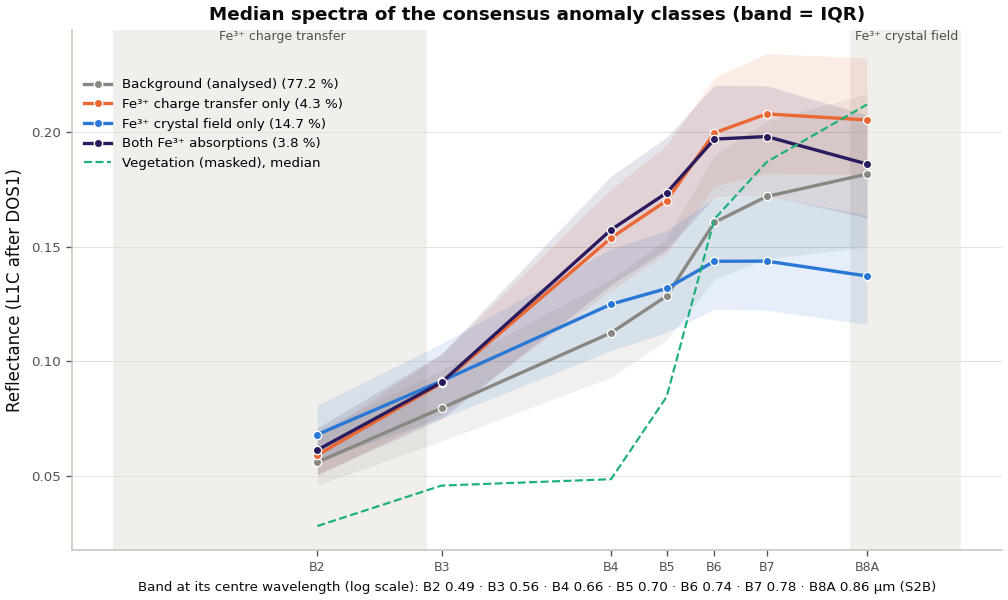

In [15]:
SPEC_BANDS = sorted([b for b in ANALYSIS_BANDS if not (b == "B8" and "B8A" in R)], key=lambda b: WL[b])   # broad B8 left out when B8A exists
wl = np.array([WL[b] for b in SPEC_BANDS])
fig, ax = plt.subplots(figsize=(8.6, 5.2))
zones = [(0.40, 0.55, "Fe³⁺ charge transfer"), (0.85, 0.95, "Fe³⁺ crystal field")]
if HAVE_SWIR:
    zones.append((2.10, 2.28, "OH / SO₄ (B12)"))
for lo_, hi_, txt in zones:
    ax.axvspan(lo_, hi_, color="#f0efec", zorder=0)
    ax.text((lo_ + hi_) / 2, 1.0, txt, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=7.5,
            color=INK_2)
line_colors = [MUTED] + OVERLAP_COLORS[1:]
for k, name in enumerate(OVERLAP_NAMES):
    m = OVERLAP == k
    if m.sum() < 5:
        continue
    spec = np.stack([R[b][m] for b in SPEC_BANDS])
    q1, med, q3 = np.nanpercentile(spec, [25, 50, 75], axis=1)
    ax.fill_between(wl, q1, q3, color=line_colors[k], alpha=0.12, lw=0)
    ax.plot(wl, med, "-o", color=line_colors[k], lw=2, ms=5, mec="white", mew=0.8,
            label=f"{name} ({100 * m.sum() / max(MASK_MIN.sum(), 1):.1f} %)")
if (MASK_CODE == 1).sum() >= 5:
    vspec = np.nanmedian(np.stack([R[b][MASK_CODE == 1] for b in SPEC_BANDS]), axis=1)
    ax.plot(wl, vspec, "--", color=SERIES[2], lw=1.3, label="Vegetation (masked), median")
ax.set_xscale("log")
ax.set_xticks(wl); ax.set_xticklabels(SPEC_BANDS, fontsize=7.5)
ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
ax.set_xlabel("Band at its centre wavelength (log scale): " + " · ".join(f"{b} {WL[b]:.2f}" for b in SPEC_BANDS)
              + f" µm ({PLATFORM})", fontsize=8)
ax.set_ylabel("Reflectance" + (" (L1C after DOS1)" if R_TOA is not None else " (surface)"))
ax.set_title("Median spectra of the consensus anomaly classes (band = IQR)", fontsize=11)
style_chart(ax)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0.0, 0.93))
fig.tight_layout()
save_fig(fig, "fig_15_anomaly_class_spectra")
plt.show()

## 11 · Spectral Angle Mapper: image endmember

SAM measures the angle (radians) between each pixel spectrum and a reference, independent of brightness (Kruse et
al., 1993). The reference is the **median spectrum of pixels in the top 5 % of both B4/B2 and the Crósta
iron-oxide component**. Bands: `SAM_BANDS` (default B2–B7 and B8A, plus B11 and B12 with SWIR; the broad B8 is left
out because it overlaps B7 and B8A). With 7–9 broad bands a small angle means a *similar spectral shape*, not the
same mineral.

SAM bands: B2, B3, B4, B5, B6, B7, B8A
Image endmember: top 5 % of B4/B2 AND Crósta Fe; n = 344 px
Endmember reflectance: B2 0.060, B3 0.092, B4 0.172, B5 0.188, B6 0.213, B7 0.215, B8A 0.205
  saved  fig_16_sam_image_endmember.png  +  fig_16_sam_image_endmember.pdf   (400 dpi)


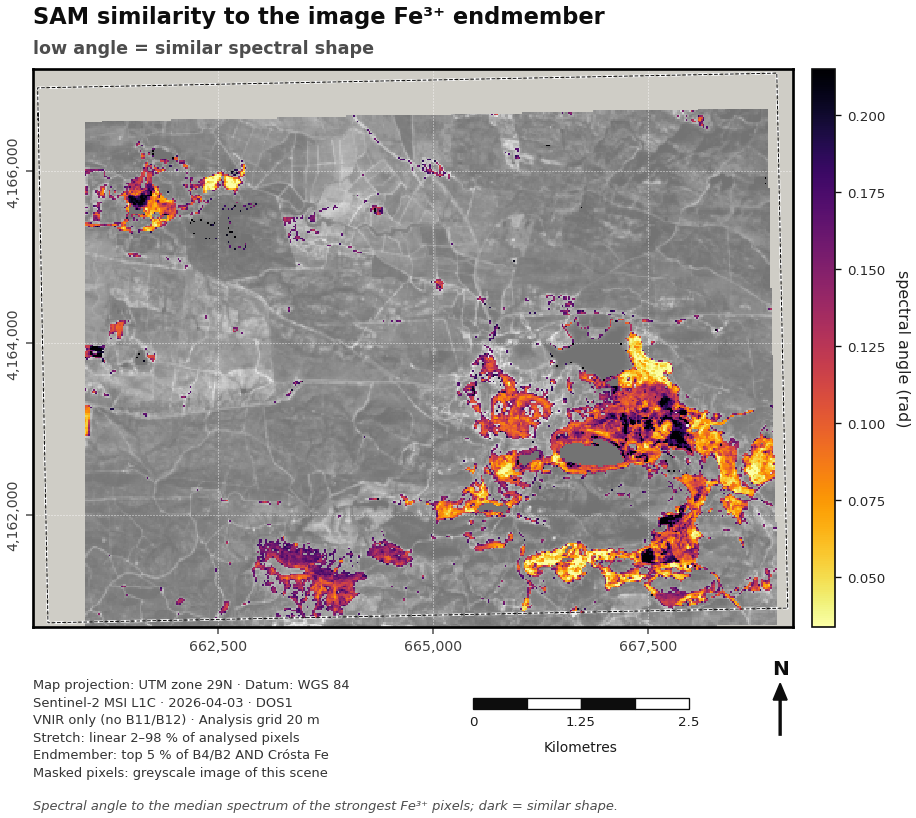

In [16]:
def sam_angle(flat, ref):
    ref = np.asarray(ref, float)
    num = flat @ ref
    den = np.linalg.norm(flat, axis=1) * np.linalg.norm(ref)
    with np.errstate(divide="ignore", invalid="ignore"):
        cos = np.clip(num / den, -1, 1)
    return np.arccos(cos)

if isinstance(SAM_BANDS, str) and SAM_BANDS == "auto":
    SAM_BAND_LIST = [b for b in ["B2", "B3", "B4", "B5", "B6", "B7", "B8A", "B11", "B12"] if b in R]
else:
    SAM_BAND_LIST = [b for b in SAM_BANDS if b in R]
SAM_OK = MASK_MIN.copy()
for b in SAM_BAND_LIST:
    SAM_OK &= np.isfinite(R[b])
flat_min = np.stack([R[b][SAM_OK] for b in SAM_BAND_LIST], axis=1).astype("float64")

_t_ratio = np.nanpercentile(IDX["Fe3_B4B2"][MASK_MIN], 95)
_t_pc = np.nanpercentile(CR_FE["image"][MASK_MIN], 95)
EM_SEL = SAM_OK & (IDX["Fe3_B4B2"] >= _t_ratio) & (CR_FE["image"] >= _t_pc)
em_rule = "top 5 % of B4/B2 AND Crósta Fe"
if EM_SEL.sum() < 20:
    EM_SEL = SAM_OK & (IDX["Fe3_B4B2"] >= _t_ratio); em_rule = "top 5 % of B4/B2 (too few joint pixels)"
ENDMEMBER = np.array([np.median(R[b][EM_SEL]) for b in SAM_BAND_LIST])
print(f"SAM bands: {', '.join(SAM_BAND_LIST)}")
print(f"Image endmember: {em_rule}; n = {EM_SEL.sum():,} px")
print("Endmember reflectance:", ", ".join(f"{b} {v:.3f}" for b, v in zip(SAM_BAND_LIST, ENDMEMBER)))

SAM_IMG = np.full((H, W), np.nan, dtype="float32")
SAM_IMG[SAM_OK] = sam_angle(flat_min, ENDMEMBER)
fig = plot_single_band(SAM_IMG, "SAM similarity to the image Fe³⁺ endmember\nlow angle = similar spectral shape",
                       "spectral angle (rad)", cmap="inferno_r", fname="fig_16_sam_image_endmember",
                       extra=[f"Endmember: {em_rule}"],
                       caption="Spectral angle to the median spectrum of the strongest Fe³⁺ pixels; dark = similar shape.")
plt.show()

### 11·b · SAM against spectral-library endmembers (optional)

Provide **either** `LIBRARY_CSV` (a `mineral` column plus one column per SAM band, reflectance already averaged to
Sentinel-2 bands, e.g. exported from your EnMAP library notebook) **or** USGS Spectral Library v7 ASCII spectra
(`USGS_SPECTRA`) with their wavelength file (`USGS_WAVELENGTH_FILE`; Kokaly et al., 2017). USGS spectra are averaged
over each band's equivalent wavelength ± half its bandwidth for the platform in §3. This is a **boxcar
approximation** of the spectral response. Deleted channels (−1.23 × 10³⁴) are ignored. Suggested endmembers for
this setting: jarosite, goethite, hematite, schwertmannite, kaolinite, muscovite/illite, alunite and gypsum.

The notebook first prints the **angle between every pair of endmembers** at Sentinel-2 resolution. Pairs closer
than `SAM_MAX_ANGLE` cannot be separated by SAM in this scene. Pixels whose best and second-best endmembers lie
within `SAM_AMBIGUITY_MARGIN` of each other are mapped as *ambiguous* rather than forced into one class. Without
B11/B12 the clay, alunite and gypsum endmembers are separated only by their VNIR shape, so expect many ambiguous or
unclassified pixels.

In [17]:
def _read_numeric_column(path):
    vals = []
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        for line in f:
            tok = line.strip().split()
            if not tok:
                continue
            try:
                vals.append(float(tok[0]))
            except ValueError:
                continue                                   # header / text lines
    a = np.array(vals, dtype=float)
    a[a < -1e30] = np.nan                                  # USGS deleted channels
    return a

def resample_to_s2(wavelength, reflectance, bands=None):
    bands = bands or SAM_BAND_LIST
    wl_ = np.asarray(wavelength, float); rf = np.asarray(reflectance, float)
    if np.nanmax(wl_) > 100:                               # nm -> µm
        wl_ = wl_ / 1000.0
    ok = np.isfinite(wl_) & np.isfinite(rf)
    wl_, rf = wl_[ok], rf[ok]
    o = np.argsort(wl_); wl_, rf = wl_[o], rf[o]
    out = []
    for b in bands:
        c, w = S2_SRF[PLATFORM][b][0] / 1000.0, S2_SRF[PLATFORM][b][1] / 1000.0
        m = (wl_ >= c - w / 2) & (wl_ <= c + w / 2)
        if m.sum() >= 2:
            out.append(rf[m].mean())
        else:
            if c < wl_.min() or c > wl_.max():
                print(f"  WARNING: spectrum does not cover {b}")
            out.append(np.interp(c, wl_, rf))
    return np.array(out)

LIBRARY = {}
if LIBRARY_CSV:
    _lib = pd.read_csv(LIBRARY_CSV)
    _missing = [c for c in ["mineral"] + SAM_BAND_LIST if c not in _lib.columns]
    if _missing:
        raise ValueError(f"LIBRARY_CSV is missing columns: {_missing} (needed for SAM_BANDS {SAM_BAND_LIST})")
    for _, r_ in _lib.iterrows():
        LIBRARY[str(r_["mineral"])] = r_[SAM_BAND_LIST].to_numpy(dtype=float)
if USGS_SPECTRA:
    if not USGS_WAVELENGTH_FILE:
        raise ValueError("USGS_SPECTRA needs USGS_WAVELENGTH_FILE (the wavelength file of the same spectrometer/version)")
    _wl = _read_numeric_column(USGS_WAVELENGTH_FILE)
    for name, path in USGS_SPECTRA.items():
        _rf = _read_numeric_column(path)
        if _rf.size != _wl.size:
            raise ValueError(f"{name}: {_rf.size} values but the wavelength file has {_wl.size}")
        LIBRARY[name] = resample_to_s2(_wl, _rf)

SAM_LIB_CLASS = None
if LIBRARY and LEVEL == "L1C":
    print("NOTE: library spectra are surface reflectance, but this run uses L1C reflectance after DOS1. The blue and "
          "green bands especially are only approximately comparable, so treat the library classes as indicative.")
if not LIBRARY:
    print("Library SAM skipped: set LIBRARY_CSV or USGS_SPECTRA (+ USGS_WAVELENGTH_FILE) in CONFIG.")
else:
    names = list(LIBRARY)
    if len(names) > len(SERIES):
        print(f"NOTE: {len(names)} endmembers; only {len(SERIES)} distinct colours - use the table and facets.")
    LIB_TABLE = pd.DataFrame([{"mineral": n, **{b: LIBRARY[n][i] for i, b in enumerate(SAM_BAND_LIST)}} for n in names])
    LIB_TABLE.to_csv(TABLE_DIR / "tab_06_library_s2_bands.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
    sep = np.array([[float(sam_angle(LIBRARY[a][None, :], LIBRARY[b])[0]) for b in names] for a in names])
    SEP_TABLE = pd.DataFrame(sep, index=names, columns=names)
    SEP_TABLE.to_csv(TABLE_DIR / "tab_07_library_separability_rad.csv", float_format="%.4f", encoding="utf-8-sig")
    print(f"Angle between library endmembers at Sentinel-2 resolution ({len(SAM_BAND_LIST)} bands, rad):")
    print(SEP_TABLE.round(3).to_string())
    for i, a in enumerate(names):
        for j, b in enumerate(names):
            if j > i and sep[i, j] < SAM_MAX_ANGLE:
                print(f"  NOT SEPARABLE at SAM_MAX_ANGLE = {SAM_MAX_ANGLE}: {a} vs {b} ({sep[i, j]:.3f} rad)")

    ang = np.stack([sam_angle(flat_min, LIBRARY[n]) for n in names])          # (n_lib, N)
    order_ = np.argsort(ang, axis=0)
    best = order_[0]; best_ang = ang[best, np.arange(ang.shape[1])]
    second_ang = ang[order_[1], np.arange(ang.shape[1])] if len(names) > 1 else np.full_like(best_ang, np.inf)
    cls_flat = np.where(best_ang <= SAM_MAX_ANGLE, best, len(names) + 1)
    cls_flat = np.where((best_ang <= SAM_MAX_ANGLE) & (second_ang - best_ang < SAM_AMBIGUITY_MARGIN), len(names), cls_flat)
    SAM_LIB_CLASS = np.full((H, W), -1, dtype=np.int16)
    SAM_LIB_CLASS[SAM_OK] = cls_flat
    lib_colors = [SERIES[i % len(SERIES)] for i in range(len(names))] + ["#898781", "#e1e0d9"]
    lib_labels = names + [f"Ambiguous (2 endmembers within {SAM_AMBIGUITY_MARGIN:g} rad)",
                          f"Unclassified (> {SAM_MAX_ANGLE:g} rad)"]
    rows = []
    for i, n in enumerate(lib_labels):
        cnt = int((cls_flat == i).sum())
        rows.append({"class": n, "pixels": cnt, "area_km2": round(cnt * PIXEL_AREA_KM2, 3),
                     "percent_of_analysed": round(100 * cnt / max(len(cls_flat), 1), 1),
                     "median_angle_rad": float(np.median(best_ang[cls_flat == i])) if cnt else np.nan})
    SAM_LIB_TABLE = pd.DataFrame(rows)
    SAM_LIB_TABLE.to_csv(TABLE_DIR / "tab_08_sam_library_classes.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
    print(SAM_LIB_TABLE.to_string(index=False))

    wl_sam = np.array([WL[b] for b in SAM_BAND_LIST])
    fig, ax = plt.subplots(figsize=(8.2, 4.8))
    for i, n in enumerate(names):
        ax.plot(wl_sam, LIBRARY[n], "-o", color=lib_colors[i], lw=2, ms=5, mec="white", mew=0.8, label=n)
    ax.plot(wl_sam, ENDMEMBER, "-o", color=INK, lw=1.2, ms=4.5, mec="white", mew=0.6, label="image endmember (§11)")
    ax.set_xscale("log"); ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
    ax.set_xticks(wl_sam); ax.set_xticklabels(SAM_BAND_LIST, fontsize=7.5)
    ax.set_xlabel("Band at its centre wavelength (log scale): " + " · ".join(f"{b} {WL[b]:.2f}" for b in SAM_BAND_LIST)
                  + " µm", fontsize=8)
    ax.set_ylabel("Reflectance")
    ax.set_title("Library endmembers at Sentinel-2 resolution", fontsize=11)
    style_chart(ax); ax.legend(fontsize=8, ncol=2)
    fig.tight_layout(); save_fig(fig, "fig_17_library_endmembers_s2"); plt.show()

    fig = plot_categorical(SAM_LIB_CLASS, "SAM classification: library endmembers", lib_colors, lib_labels,
                           fname="fig_18_sam_library_classes", key_title="Minimum angle",
                           extra=[f"Max angle {SAM_MAX_ANGLE:g} rad · {len(SAM_BAND_LIST)} bands"],
                           caption="Spectral-shape similarity to library endmembers, not mineral identification.")
    plt.show()
    ang_maps = []
    for i in range(len(names)):
        a_ = np.full((H, W), np.nan, dtype="float32"); a_[SAM_OK] = ang[i]; ang_maps.append(a_)
    fig = panel_maps(ang_maps, [f"Angle to {n}" for n in names], ["inferno_r"] * len(names),
                     "SAM angle to each library endmember (dark = similar)", fname="fig_19_sam_library_angles",
                     cbar_labels=["rad"] * len(names))
    plt.show()

Library SAM skipped: set LIBRARY_CSV or USGS_SPECTRA (+ USGS_WAVELENGTH_FILE) in CONFIG.


## 12 · Robustness checks

Five questions decide how confidently the maps can be described in the thesis:

1. **Do independent methods agree?** Spearman rank correlations between all layers, and the Jaccard overlap of
   their top `TOP_PERCENT` % pixels. Two unrelated top-10 % masks overlap by only about 0.05.
2. **Does the Crósta result depend on the PCA variant?** Correlation- versus covariance-matrix PCA.
3. **Is residual vegetation still driving an index?** Spearman ρ between each layer and NDVI inside the mineral
   mask. |ρ| ≥ 0.5 flags a layer whose pattern partly tracks sparse vegetation below the NDVI threshold. B6/B8A and
   the NIR depth are the most likely to be flagged.
4. **How sensitive are the anomalies to the vegetation threshold?** Anomaly areas are recomputed for each NDVI
   threshold in `NDVI_SENSITIVITY`, holding the index thresholds of §9 fixed.
5. **L1C only: how much do the Fe³⁺ anomalies depend on the dark-object subtraction?** B4/B2 and B4/B3 are
   recomputed from top-of-atmosphere reflectance. The top `TOP_PERCENT` % with and without DOS1 are then compared.
   A low overlap means the L1C Fe³⁺ maps are not robust, and L2A is needed.

  saved  fig_20_layer_spearman_matrix.png  +  fig_20_layer_spearman_matrix.pdf   (400 dpi)


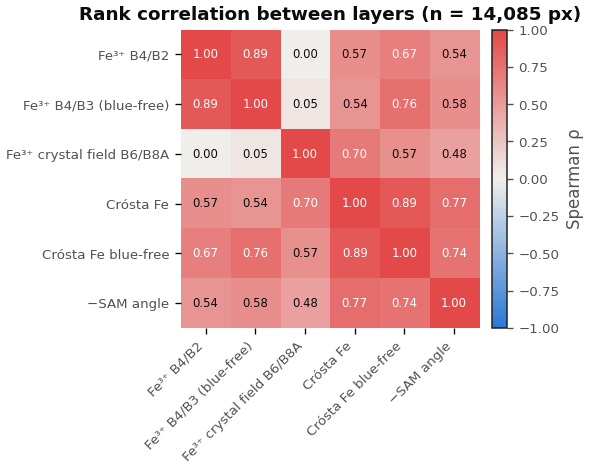

Layer vs NDVI inside the mineral mask (|rho| >= 0.5 = residual vegetation still drives the layer):
                    layer  spearman_rho_with_NDVI     n                 flag
               Fe³⁺ B4/B2                   0.222 14085                     
   Fe³⁺ B4/B3 (blue-free)                   0.151 14085                     
Fe³⁺ crystal field B6/B8A                  -0.860 14085 vegetation-sensitive
                Crósta Fe                  -0.536 14085 vegetation-sensitive
      Crósta Fe blue-free                  -0.338 14085                     
               −SAM angle                  -0.365 14085                     

                              comparison    layer_a                   layer_b  spearman_rho  jaccard_top10pct  jaccard_if_unrelated
                     ratio vs PCA (Fe³⁺) Fe³⁺ B4/B2                 Crósta Fe         0.574             0.377                 0.053
                 blue vs blue-free ratio Fe³⁺ B4/B2    Fe³⁺ B4/B3 (blue-free)         0.894      

In [ ]:
ROBUST_LAYERS = {IDX_LABEL[k]: IDX[k] for k in IDX}
ROBUST_LAYERS["Crósta Fe"] = CR_FE["image"]
if CR_FE3 is not None:
    ROBUST_LAYERS["Crósta Fe blue-free"] = CR_FE3["image"]
if CR_OH is not None:
    ROBUST_LAYERS["Crósta OH"] = CR_OH["image"]
ROBUST_LAYERS["-SAM angle"] = -SAM_IMG
keys = list(ROBUST_LAYERS)
common = MASK_MIN.copy()
for a in ROBUST_LAYERS.values():
    common &= np.isfinite(a)
idx_c = np.flatnonzero(common)
if idx_c.size > 50000:
    idx_c = np.random.default_rng(RANDOM_STATE).choice(idx_c, 50000, replace=False)
M = np.stack([ROBUST_LAYERS[k].ravel()[idx_c] for k in keys], axis=1)
RHO = np.asarray(stats.spearmanr(M)[0], dtype=float)
RHO_TABLE = pd.DataFrame(RHO, index=keys, columns=keys)
RHO_TABLE.to_csv(TABLE_DIR / "tab_09_spearman_matrix.csv", float_format="%.3f", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(1.0 + 0.72 * len(keys), 0.4 + 0.62 * len(keys)))
im = ax.imshow(RHO, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(keys))); ax.set_xticklabels(keys, rotation=45, ha="right", fontsize=8, color=INK_2)
ax.set_yticks(range(len(keys))); ax.set_yticklabels(keys, fontsize=8, color=INK_2)
for i in range(len(keys)):
    for j in range(len(keys)):
        ax.text(j, i, f"{RHO[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(RHO[i, j]) > 0.6 else INK)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.set_label("Spearman ρ", color=INK_2)
cb.ax.tick_params(colors=INK_2)
ax.set_title(f"Rank correlation between layers (n = {idx_c.size:,} px)", fontsize=11, color=INK)
fig.tight_layout(); save_fig(fig, "fig_20_layer_spearman_matrix"); plt.show()

def top_mask(arr, pct=TOP_PERCENT, mask=None):
    ok = (MASK_MIN if mask is None else mask) & np.isfinite(arr)
    t = np.percentile(arr[ok], 100 - pct)
    return ok & (arr >= t)

def jaccard(a, b):
    u = (a | b).sum()
    return float((a & b).sum() / u) if u else np.nan

L = IDX_LABEL
pairs = [(L["Fe3_B4B2"], "Crósta Fe", "ratio vs PCA (Fe³⁺)"), (L["Fe3_B4B2"], L["Fe3_B4B3"], "blue vs blue-free ratio"),
         (L["Fe3_B4B2"], "-SAM angle", "ratio vs SAM (image endmember)")]
if CR_FE3 is not None:
    pairs.append(("Crósta Fe", "Crósta Fe blue-free", "blue vs blue-free Crósta"))
if "FeCF_B6B8A" in IDX:
    pairs.append((L["Fe3_B4B2"], L["FeCF_B6B8A"], "charge transfer vs crystal field"))
if HAVE_SWIR:
    pairs += [(L["OH_SO4_B11B12"], "Crósta OH", "ratio vs PCA (OH/SO₄)"), (L["Fe3_B4B2"], L["OH_SO4_B11B12"], "Fe³⁺ vs OH/SO₄")]
p = TOP_PERCENT / 100
agree_rows = [{"comparison": lab, "layer_a": a, "layer_b": b, "spearman_rho": RHO_TABLE.loc[a, b],
               f"jaccard_top{TOP_PERCENT}pct": jaccard(top_mask(ROBUST_LAYERS[a]), top_mask(ROBUST_LAYERS[b])),
               "jaccard_if_unrelated": p * p / (2 * p - p * p)} for a, b, lab in pairs]
_variants = [(CR_FE, "FE", "Crósta Fe: correlation vs covariance PCA")]
if CR_OH is not None:
    _variants.append((CR_OH, "OH", "Crósta OH: correlation vs covariance PCA"))
for base_, set_key, lab in _variants:
    alt_ = crosta_fpcs(*CROSTA_SETS[set_key], standardise=not CROSTA_STANDARDISE, verbose=False)
    agree_rows.append({"comparison": lab, "layer_a": f"PC{base_['pc']+1}", "layer_b": f"PC{alt_['pc']+1}",
                       "spearman_rho": spearman_layers(base_["image"], alt_["image"])[0],
                       f"jaccard_top{TOP_PERCENT}pct": jaccard(top_mask(base_["image"]), top_mask(alt_["image"])),
                       "jaccard_if_unrelated": p * p / (2 * p - p * p)})
AGREE_TABLE = pd.DataFrame(agree_rows)
AGREE_TABLE.to_csv(TABLE_DIR / "tab_10_method_agreement.csv", index=False, float_format="%.3f", encoding="utf-8-sig")

veg_rows = []
for k_, a_ in ROBUST_LAYERS.items():
    rho_, n_ = spearman_layers(a_, NDVI, mask=MASK_MIN)
    veg_rows.append({"layer": k_, "spearman_rho_with_NDVI": rho_, "n": n_,
                     "flag": "vegetation-sensitive" if np.isfinite(rho_) and abs(rho_) >= 0.5 else ""})
VEG_CHECK = pd.DataFrame(veg_rows)
VEG_CHECK.to_csv(TABLE_DIR / "tab_11_layer_vs_ndvi.csv", index=False, float_format="%.3f", encoding="utf-8-sig")
print("Layer vs NDVI inside the mineral mask (|rho| >= 0.5 = residual vegetation still drives the layer):")
print(VEG_CHECK.round(3).to_string(index=False))
print()
print(AGREE_TABLE.round(3).to_string(index=False))

Index thresholds held fixed (mean+1sd at NDVI 0.3): B4/B2 >= 2.338, B6 / B8A >= 1.012
 ndvi_threshold  analysed_km2  fe3_B4B2_anomaly_km2  jaccard_fe3_vs_config  FeCF_B6B8A_anomaly_km2  jaccard_FeCF_B6B8A_vs_config
           0.20         3.518                 0.558                  0.727                   1.043                           1.0
           0.25         4.485                 0.685                  0.892                   1.043                           1.0
           0.30         5.634                 0.768                  1.000                   1.043                           1.0
           0.35         6.996                 0.831                  0.924                   1.043                           1.0
           0.40         8.971                 0.868                  0.885                   1.043                           1.0
  saved  fig_21_ndvi_threshold_sensitivity.png  +  fig_21_ndvi_threshold_sensitivity.pdf   (400 dpi)


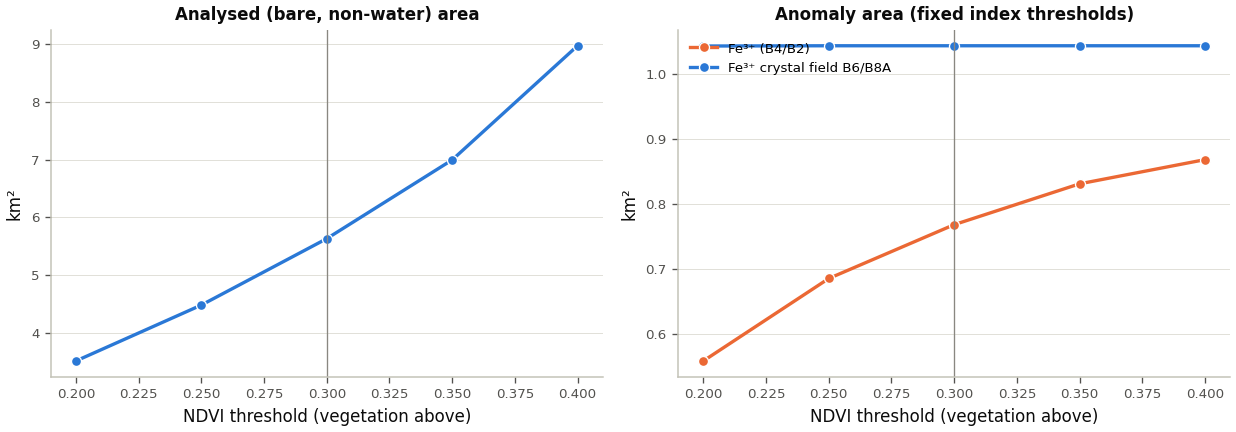


L1C: Fe³⁺ ratios from TOA reflectance vs after DOS1 (low Jaccard = anomalies depend on the correction):
                 index  spearman_rho_TOA_vs_DOS1     n  jaccard_top10pct  median_TOA  median_DOS1
            Fe³⁺ B4/B2                     0.736 14085             0.403       1.147        2.018
Fe³⁺ B4/B3 (blue-free)                     0.893 14085             0.573       1.162        1.434


In [19]:
t_fe = THR["Fe3_B4B2"][LVL1]
base_fe = MASK_MIN & (IDX["Fe3_B4B2"] >= t_fe)
if LAYER_B_KEY:
    t_b = THR[LAYER_B_KEY][LVL1]
    base_b = MASK_MIN & (IDX[LAYER_B_KEY] >= t_b)
sens_rows = []
for t in NDVI_SENSITIVITY:
    m = BASE_NOVEG & (NDVI <= t)
    row = {"ndvi_threshold": t, "analysed_km2": m.sum() * PIXEL_AREA_KM2}
    fe = m & (RAW_IDX["Fe3_B4B2"] >= t_fe)
    row.update({"fe3_B4B2_anomaly_km2": fe.sum() * PIXEL_AREA_KM2, "jaccard_fe3_vs_config": jaccard(fe, base_fe)})
    if LAYER_B_KEY:
        bb = m & (RAW_IDX[LAYER_B_KEY] >= t_b)
        row.update({f"{LAYER_B_KEY}_anomaly_km2": bb.sum() * PIXEL_AREA_KM2,
                    f"jaccard_{LAYER_B_KEY}_vs_config": jaccard(bb, base_b)})
    sens_rows.append(row)
SENS_TABLE = pd.DataFrame(sens_rows)
SENS_TABLE.to_csv(TABLE_DIR / "tab_12_ndvi_sensitivity.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
print(f"Index thresholds held fixed ({LVL1} at NDVI {NDVI_VEG_THRESHOLD:g}): B4/B2 >= {t_fe:.3f}"
      + (f", {IDX_FORMULA[LAYER_B_KEY]} >= {t_b:.3f}" if LAYER_B_KEY else ""))
print(SENS_TABLE.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
ax = axes[0]
ax.plot(SENS_TABLE["ndvi_threshold"], SENS_TABLE["analysed_km2"], "-o", color=SERIES[0], lw=2, ms=6, mec="white", mew=0.8)
ax.set_title("Analysed (bare, non-water) area", fontsize=10); ax.set_ylabel("km²")
ax2 = axes[1]
_series = [("fe3_B4B2_anomaly_km2", SERIES[1], "Fe³⁺ (B4/B2)")]
if LAYER_B_KEY:
    _series.append((f"{LAYER_B_KEY}_anomaly_km2", SERIES[0], IDX_LABEL[LAYER_B_KEY]))
for col, color, lab in _series:
    ax2.plot(SENS_TABLE["ndvi_threshold"], SENS_TABLE[col], "-o", color=color, lw=2, ms=6, mec="white", mew=0.8, label=lab)
ax2.set_title("Anomaly area (fixed index thresholds)", fontsize=10); ax2.set_ylabel("km²")
ax2.legend(fontsize=8, loc="upper left")
for a_ in axes:
    a_.axvline(NDVI_VEG_THRESHOLD, color=MUTED, lw=0.8)
    a_.set_xlabel("NDVI threshold (vegetation above)")
    style_chart(a_)
fig.tight_layout(); save_fig(fig, "fig_21_ndvi_threshold_sensitivity"); plt.show()

# L1C only: dependence of the Fe3+ anomalies on the dark-object subtraction
if R_TOA is not None:
    dos_rows = []
    for key, (nb, db) in {"Fe3_B4B2": ("B4", "B2"), "Fe3_B4B3": ("B4", "B3")}.items():
        toa = mineral_layer(safe_ratio(R_TOA[nb], R_TOA[db]))
        rho_, n_ = spearman_layers(toa, IDX[key], mask=MASK_MIN)
        dos_rows.append({"index": IDX_LABEL[key], "spearman_rho_TOA_vs_DOS1": rho_, "n": n_,
                         f"jaccard_top{TOP_PERCENT}pct": jaccard(top_mask(toa), top_mask(IDX[key])),
                         "median_TOA": np.nanmedian(toa), "median_DOS1": np.nanmedian(IDX[key])})
    DOS_SENS = pd.DataFrame(dos_rows)
    DOS_SENS.to_csv(TABLE_DIR / "tab_13_dos_sensitivity_L1C.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
    print("\nL1C: Fe³⁺ ratios from TOA reflectance vs after DOS1 (low Jaccard = anomalies depend on the correction):")
    print(DOS_SENS.round(3).to_string(index=False))

## 13 · Validation against field samples and reference rasters (optional)

**Samples.** Each layer is averaged over a `SAMPLE_WINDOW` × `SAMPLE_WINDOW` pixel window (mineral-mask pixels only)
around every sample and compared with the sample attributes using Spearman's ρ. For a class column (e.g.
`FTIR_mineral`) the notebook draws box plots and runs a Mann–Whitney U test (two groups) or a Kruskal–Wallis test
(more than two). Hand samples and pixels differ in support: a sample represents centimetres, a 20 m pixel 400 m²
of mixed surface, and sampling and image dates differ. Read ρ as *consistency*, not calibration, and always report
n.

**Reference rasters.** EnMAP products (e.g. a jarosite band-depth map) or the Landsat r6 GeoTIFFs are resampled
onto this grid: averaged where they are finer, nearest neighbour where they are coarser. Correlations use every
third pixel in each direction, which reduces the inflation of significance from spatial autocorrelation. For
30 m rasters, consecutive 20 m pixels share source pixels, so treat n as an upper bound. The Jaccard overlap of the
top `TOP_PERCENT` % is also reported.

In [ ]:
VAL_LAYERS = dict(ROBUST_LAYERS)
MAIN_VAL = [IDX_LABEL["Fe3_B4B2"], "Crósta Fe"] + ([IDX_LABEL[LAYER_B_KEY]] if LAYER_B_KEY else []) \
           + (["Crósta OH"] if CR_OH is not None else [])
SAMPLES = None
if not SAMPLES_CSV:
    print("Sample validation skipped: set SAMPLES_CSV (and SAMPLE_VALUE_COLS / SAMPLE_CLASS_COL) in CONFIG.")
else:
    SAMPLES = pd.read_csv(SAMPLES_CSV)
    xs = SAMPLES[SAMPLE_X_COL].astype(float).to_numpy(); ys = SAMPLES[SAMPLE_Y_COL].astype(float).to_numpy()
    if SAMPLE_CRS and rasterio.crs.CRS.from_user_input(SAMPLE_CRS) != CRS:
        xs, ys = warp_transform(SAMPLE_CRS, CRS, xs, ys); xs, ys = np.asarray(xs), np.asarray(ys)
    rows_, cols_ = rasterio.transform.rowcol(TRANSFORM, xs, ys)
    rows_, cols_ = np.asarray(rows_), np.asarray(cols_)
    half = SAMPLE_WINDOW // 2
    SAMPLES["inside_grid"] = (rows_ >= 0) & (rows_ < H) & (cols_ >= 0) & (cols_ < W)
    def _win(arr, r0, c0):
        return arr[max(r0 - half, 0):max(min(r0 + half + 1, H), 0), max(c0 - half, 0):max(min(c0 + half + 1, W), 0)]
    for key, arr in VAL_LAYERS.items():
        vals = []
        for r0, c0 in zip(rows_, cols_):
            win = _win(arr, r0, c0)
            vals.append(float(np.nanmean(win)) if win.size and np.isfinite(win).any() else np.nan)
        SAMPLES[key] = vals
    SAMPLES["analysed_px_in_window"] = [int(_win(MASK_MIN, r0, c0).sum()) for r0, c0 in zip(rows_, cols_)]
    SAMPLES["mask_class_at_sample"] = [MASK_NAMES[int(MASK_CODE[r0, c0])] if (0 <= r0 < H and 0 <= c0 < W and
                                       MASK_CODE[r0, c0] >= 0) else "outside" for r0, c0 in zip(rows_, cols_)]
    SAMPLES.to_csv(TABLE_DIR / "tab_14_samples_with_layer_values.csv", index=False, float_format="%.5f", encoding="utf-8-sig")
    n_valid = int(np.isfinite(SAMPLES[IDX_LABEL["Fe3_B4B2"]]).sum())
    print(f"Samples: {len(SAMPLES)} read, {int(SAMPLES['inside_grid'].sum())} inside the grid, "
          f"{n_valid} with analysed pixels in the {SAMPLE_WINDOW}x{SAMPLE_WINDOW} window")
    print("Mask class at the sample pixel: " + ", ".join(f"{k}: {v}" for k, v in
                                                          SAMPLES["mask_class_at_sample"].value_counts().items()))
    if n_valid < 10:
        print("  NOTE: fewer than 10 usable samples - correlations are not meaningful.")

    corr_rows = []
    for vc in SAMPLE_VALUE_COLS:
        yv = pd.to_numeric(SAMPLES[vc], errors="coerce")
        for key in VAL_LAYERS:
            ok = np.isfinite(SAMPLES[key]) & np.isfinite(yv)
            rho, pval = (stats.spearmanr(SAMPLES.loc[ok, key], yv[ok]) if ok.sum() >= 5 else (np.nan, np.nan))
            corr_rows.append({"attribute": vc, "layer": key, "n": int(ok.sum()), "spearman_rho": rho, "p_value": pval})
    if corr_rows:
        SAMPLE_CORR = pd.DataFrame(corr_rows)
        SAMPLE_CORR.to_csv(TABLE_DIR / "tab_15_sample_spearman.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
        print(SAMPLE_CORR.round(3).to_string(index=False))
        vcs = SAMPLE_VALUE_COLS[:3]
        fig, axes = plt.subplots(len(vcs), len(MAIN_VAL), figsize=(3.1 * len(MAIN_VAL), 2.8 * len(vcs)), squeeze=False)
        for i, vc in enumerate(vcs):
            yv = pd.to_numeric(SAMPLES[vc], errors="coerce")
            for j, key in enumerate(MAIN_VAL):
                ax = axes[i, j]
                ok = np.isfinite(SAMPLES[key]) & np.isfinite(yv)
                ax.scatter(SAMPLES.loc[ok, key], yv[ok], s=30, color=SERIES[0], edgecolor="white", linewidth=0.8)
                r_ = SAMPLE_CORR[(SAMPLE_CORR.attribute == vc) & (SAMPLE_CORR["layer"] == key)].iloc[0]
                ax.set_title(f"ρ = {r_.spearman_rho:.2f} (n = {r_.n})", fontsize=8.5, color=INK)
                ax.set_xlabel(key, fontsize=8); ax.set_ylabel(vc if j == 0 else "", fontsize=8)
                style_chart(ax, grid_axis="both")
        fig.suptitle("Sentinel-2 layers vs sample attributes (window means)", fontsize=11, color=INK)
        fig.tight_layout(rect=(0, 0, 1, 0.96)); save_fig(fig, "fig_22_samples_scatter"); plt.show()

    if SAMPLE_CLASS_COL:
        grp = SAMPLES[SAMPLE_CLASS_COL].astype(str)
        levels = sorted(grp.unique())
        test_rows = []
        fig, axes = plt.subplots(1, len(MAIN_VAL), figsize=(max(3.1, 0.55 * len(levels) + 1.6) * len(MAIN_VAL), 3.6),
                                 squeeze=False)
        for j, key in enumerate(MAIN_VAL):
            data = [SAMPLES.loc[(grp == g) & np.isfinite(SAMPLES[key]), key].to_numpy() for g in levels]
            ax = axes[0, j]
            ax.boxplot([d if len(d) else np.array([np.nan]) for d in data], widths=0.5, patch_artist=True,
                       boxprops=dict(facecolor="#cde2fb", edgecolor=SERIES[0]), medianprops=dict(color=INK, lw=1.5),
                       whiskerprops=dict(color=SERIES[0]), capprops=dict(color=SERIES[0]),
                       flierprops=dict(marker="o", ms=4, markerfacecolor=SERIES[0], markeredgecolor="white"))
            ax.set_xticks(range(1, len(levels) + 1))
            ax.set_xticklabels([f"{g}\n(n={len(d)})" for g, d in zip(levels, data)], fontsize=7.5, rotation=0)
            ax.set_title(key, fontsize=10); ax.set_xlabel(SAMPLE_CLASS_COL, fontsize=8)
            style_chart(ax)
            usable = [d for d in data if len(d) >= 3]
            if len(usable) == 2 and len(levels) == 2:
                stat, pval = stats.mannwhitneyu(usable[0], usable[1], alternative="two-sided"); test = "Mann–Whitney U"
            elif len(usable) >= 3:
                stat, pval = stats.kruskal(*usable); test = "Kruskal–Wallis H"
            else:
                stat, pval, test = np.nan, np.nan, "too few samples"
            test_rows.append({"layer": key, "test": test, "statistic": stat, "p_value": pval,
                              **{f"median[{g}]": (np.median(d) if len(d) else np.nan) for g, d in zip(levels, data)}})
        fig.suptitle(f"Layer values by {SAMPLE_CLASS_COL}", fontsize=11, color=INK)
        fig.tight_layout(rect=(0, 0, 1, 0.94)); save_fig(fig, "fig_23_samples_by_class"); plt.show()
        SAMPLE_TESTS = pd.DataFrame(test_rows)
        SAMPLE_TESTS.to_csv(TABLE_DIR / "tab_16_sample_group_tests.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
        print(SAMPLE_TESTS.round(4).to_string(index=False))

    fig = plot_categorical(OVERLAP, "Samples over the consensus anomaly map", OVERLAP_COLORS, OVERLAP_NAMES,
                           fname="fig_24_samples_on_anomaly_map", key_title="Anomaly class", points=(xs, ys),
                           extra=[f"{len(SAMPLES)} samples (black dots)"],
                           caption="Sample locations over the consensus anomaly classes of §9.")
    plt.show()

Sample validation skipped: set SAMPLES_CSV (and SAMPLE_VALUE_COLS / SAMPLE_CLASS_COL) in CONFIG.


In [21]:
REFERENCE = {}
if not REFERENCE_RASTERS:
    print("Reference-raster comparison skipped: set REFERENCE_RASTERS in CONFIG (EnMAP products, Landsat r6 GeoTIFFs).")
else:
    ref_rows = []
    thin = np.zeros((H, W), bool); thin[::3, ::3] = True
    for label, spec_ in REFERENCE_RASTERS.items():
        path, band_ = (spec_, 1) if isinstance(spec_, (str, Path)) else (spec_[0], int(spec_[1]))
        arr = np.full((H, W), np.nan, dtype="float32")
        with rasterio.open(path) as src:
            finer = _file_res_m(src) < 0.95 * ANALYSIS_RES_M
            reproject(source=rasterio.band(src, band_), destination=arr, src_transform=src.transform, src_crs=src.crs,
                      src_nodata=src.nodata, dst_transform=TRANSFORM, dst_crs=CRS, dst_nodata=np.nan,
                      resampling=Resampling.average if finer else Resampling.nearest)
        REFERENCE[label] = arr
        ok = MASK_MIN & np.isfinite(arr)
        print(f"{label}: {int(ok.sum()):,} analysed pixels with reference values")
        if ok.sum() < 30:
            print("  too few overlapping pixels - check CRS and extent")
            continue
        for key, lay in VAL_LAYERS.items():
            rho, n = spearman_layers(arr, lay, mask=ok & thin)
            ref_rows.append({"reference": label, "sentinel2_layer": key, "n_thinned": n, "spearman_rho": rho,
                             f"jaccard_top{TOP_PERCENT}pct": jaccard(top_mask(arr, mask=ok), top_mask(lay, mask=ok))})
        show = MAIN_VAL[:2] if not LAYER_B_KEY else [IDX_LABEL["Fe3_B4B2"], IDX_LABEL[LAYER_B_KEY]]
        fig, axes = plt.subplots(1, len(show), figsize=(4.8 * len(show), 4.0), squeeze=False)
        for ax, key in zip(axes.ravel(), show):
            m = ok & thin & np.isfinite(VAL_LAYERS[key])
            if m.sum() < 10:
                ax.text(0.5, 0.5, "too few overlapping pixels", ha="center", va="center", transform=ax.transAxes, color=INK_2)
                continue
            hb = ax.hexbin(VAL_LAYERS[key][m], arr[m], gridsize=40, cmap=SEQ_BLUE, mincnt=1, linewidths=0)
            ax.set_xlabel(f"Sentinel-2 {key}"); ax.set_ylabel(label)
            r_ = [e for e in ref_rows if e["reference"] == label and e["sentinel2_layer"] == key][0]
            ax.set_title(f"ρ = {r_['spearman_rho']:.2f} (every 3rd pixel, n = {r_['n_thinned']:,})", fontsize=9.5)
            style_chart(ax, grid_axis="both")
            fig.colorbar(hb, ax=ax, fraction=0.046, pad=0.03).set_label("pixels", color=INK_2)
        fig.tight_layout()
        save_fig(fig, f"fig_25_reference_{re.sub(r'[^A-Za-z0-9]+', '_', label).strip('_')}")
        plt.show()
    if ref_rows:
        REFERENCE_TABLE = pd.DataFrame(ref_rows)
        REFERENCE_TABLE.to_csv(TABLE_DIR / "tab_17_reference_rasters.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
        print(REFERENCE_TABLE.round(3).to_string(index=False))

Reference-raster comparison skipped: set REFERENCE_RASTERS in CONFIG (EnMAP products, Landsat r6 GeoTIFFs).


## 14 · Export: GeoTIFFs and tables

All index layers, Crósta components, SAM angles, NDVI, the water index, the analysis mask and the anomaly classes are
written as GeoTIFFs on the analysis grid (EPSG:32629). Float layers use NaN as nodata and class layers use −1. They
open directly in QGIS/ArcGIS and can be read back into the Landsat, EnMAP and geostatistics notebooks.

In [22]:
def write_geotiff(name, arr, dtype="float32", nodata=np.nan):
    path = RASTER_DIR / f"{name}.tif"
    profile = dict(driver="GTiff", height=H, width=W, count=1, dtype=dtype, crs=CRS, transform=TRANSFORM,
                   nodata=nodata, compress="deflate")
    with rasterio.open(path, "w", **profile) as dst:
        dst.write(np.asarray(arr).astype(dtype), 1)
    return path.name

if EXPORT_GEOTIFF:
    written = [write_geotiff(f"idx_{k}", a) for k, a in IDX.items()]
    written += [write_geotiff("crosta_iron_oxide", CR_FE["image"]), write_geotiff("sam_angle_image_endmember", SAM_IMG),
                write_geotiff("ndvi", NDVI), write_geotiff("water_index", WATER_IDX),
                write_geotiff("mask_classes", MASK_CODE, "int16", -1),
                write_geotiff("anomaly_overlap_classes", OVERLAP, "int16", -1)]
    if CR_FE3 is not None:
        written.append(write_geotiff("crosta_iron_oxide_bluefree", CR_FE3["image"]))
    if CR_OH is not None:
        written.append(write_geotiff("crosta_hydroxyl", CR_OH["image"]))
    if SAM_LIB_CLASS is not None:
        written.append(write_geotiff("sam_library_classes", SAM_LIB_CLASS, "int16", -1))
    print(f"{len(written)} GeoTIFFs written to {RASTER_DIR}:")
    print("  " + "\n  ".join(written))

10 GeoTIFFs written to sentinel2_mineral_maps_r4\rasters:
  idx_Fe3_B4B2.tif
  idx_Fe3_B4B3.tif
  idx_FeCF_B6B8A.tif
  crosta_iron_oxide.tif
  sam_angle_image_endmember.tif
  ndvi.tif
  water_index.tif
  mask_classes.tif
  anomaly_overlap_classes.tif
  crosta_iron_oxide_bluefree.tif


In [23]:
figs = sorted(p.name for p in FIG_DIR.glob("*.png"))
tabs = sorted(p.name for p in TABLE_DIR.glob("*.csv"))
print(f"Run: {SENSOR_LABEL} · {MODE_LABEL} · {PIXEL_NOTE}")
print(f"Figures ({len(figs)}) in {FIG_DIR}  [PNG {FIG_DPI} dpi + vector PDF]:")
print("  " + "\n  ".join(figs))
print(f"\nTables ({len(tabs)}) in {TABLE_DIR}  [UTF-8 with BOM, so Excel shows Fe³⁺ and ρ correctly]:")
print("  " + "\n  ".join(tabs))

Run: Sentinel-2 MSI L1C · 2026-04-03 · DOS1 · VNIR only (no B11/B12) · Analysis grid 20 m
Figures (17) in sentinel2_mineral_maps_r4\figures  [PNG 400 dpi + vector PDF]:
  fig_00_ndvi.png
  fig_00b_analysis_mask.png
  fig_01_natural_colour.png
  fig_02_colour_infrared.png
  fig_04_index_Fe3_B4B2.png
  fig_05_index_FeCF_B6B8A.png
  fig_08_supplementary_indices.png
  fig_09_index_distributions.png
  fig_10_ratio_rgb.png
  fig_11_crosta_iron_oxide.png
  fig_13_ca_fractal_thresholds.png
  fig_14_consensus_anomaly_overlap.png
  fig_14b_individual_anomaly_layers.png
  fig_15_anomaly_class_spectra.png
  fig_16_sam_image_endmember.png
  fig_20_layer_spearman_matrix.png
  fig_21_ndvi_threshold_sensitivity.png

Tables (13) in sentinel2_mineral_maps_r4\tables  [UTF-8 with BOM, so Excel shows Fe³⁺ and ρ correctly]:
  tab_00_bands_and_scaling.csv
  tab_00b_dos1_haze.csv
  tab_01_mask_summary.csv
  tab_02_index_statistics.csv
  tab_03_crosta_selection.csv
  tab_04_anomaly_thresholds.csv
  tab_05_over